# The Midnight Queue — Assignment 2
**24i-2573 · DS-B** · s = 242573 · K = 25 + (s mod 226) = **100** · every random choice is seeded with s

Open in Colab → **Runtime → Run all**. The dataset is downloaded automatically (no uploads).

* `QUICK = True` runs every problem on small sizes (a few minutes, good for the demo).
* `QUICK = False` runs the full assignment sizes (n up to 284,807, median of 5, 5-minute DNF rule; takes hours).

In [1]:
QUICK = True        # True: small sizes for the demo | False: full assignment run (slow)

import os, sys, time, math, random, platform, statistics
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- dataset: use a local creditcard.csv if present, otherwise download it from Kaggle
CSV = "creditcard.csv"
if not os.path.exists(CSV):
    import kagglehub
    CSV = os.path.join(kagglehub.dataset_download("mlg-ulb/creditcardfraud"), "creditcard.csv")

S = 242573                      # roll number digits -> seed for everything
K = 25 + (S % 226)              # personal shift capacity = 100
DNF_SECONDS = 300               # a single run over 5 minutes = DNF
if QUICK:
    SIZES, REPS, D_SIZES, E_WINDOWS, E_REPS = [1_000, 10_000], 3, [10_000], [3600, 600], 1
else:
    SIZES, REPS, D_SIZES, E_WINDOWS, E_REPS = [1_000, 10_000, 100_000, 284_807], 5, [100_000, 284_807], [3600, 600], 3
CONDITIONS = ["C1", "C2", "C3", "C4", "C5", "C6"]

print("K =", K, "| sizes:", SIZES, "| reps:", REPS)
print("Python", sys.version.split()[0], "|", platform.platform(), "|", platform.processor() or platform.machine())

K = 100 | sizes: [1000, 10000] | reps: 3
Python 3.13.17 | Linux-6.18.44-fc-v338-x86_64-with-glibc2.39 | x86_64


## Problem B — the contenders
Hand-written, no built-in sort inside. Every sort returns `(sorted_list, Stats)`.

**Counting:** a *comparison* is one `<` / `<=` / `>` between two keys (loop/index tests not counted);
a *move* is one write of a key into a list slot (a swap = 2 moves); *extra* = peak extra slots.

In [2]:
"""Hand-written contenders for The Midnight Queue. No built-in sort inside.

Elements are integer keys (smaller key = earlier in the triage queue), so every
comparison is one `<` on two ints.

COUNTING DEFINITION (as stated in the report)
  comparison : one evaluation of a `<` / `<=` between two KEYS. Index/loop
               tests (i < n, lo < hi) are not counted.
  move       : one write of a key into a list slot (the array or any auxiliary
               list). A swap = 2 moves. Reading is free.

Every sort returns (sorted_list, Stats). `deadline` (a perf_counter value) makes
a run raise DNF so the harness can apply the 5-minute rule.
"""
import random
from time import perf_counter


class DNF(Exception):
    pass


class Stats:
    __slots__ = ("comps", "moves", "peak_extra")

    def __init__(self, comps=0, moves=0, peak_extra=0):
        self.comps, self.moves, self.peak_extra = comps, moves, peak_extra

    def __repr__(self):
        return f"Stats(comps={self.comps}, moves={self.moves}, extra={self.peak_extra})"


def _check(deadline):
    if deadline is not None and perf_counter() > deadline:
        raise DNF


# ----------------------------------------------------------------- insertion
def insertion_sort(a, deadline=None):
    a = list(a)
    c = m = 0
    for i in range(1, len(a)):
        if not i & 1023:
            _check(deadline)
        x = a[i]
        j = i - 1
        while j >= 0:
            c += 1
            if a[j] > x:
                a[j + 1] = a[j]; m += 1
                j -= 1
            else:
                break
        a[j + 1] = x; m += 1
    return a, Stats(c, m, 0)


# --------------------------------------------------------------------- merge
def merge_sort(a, deadline=None):
    a = list(a)
    n = len(a)
    st = Stats(0, 0, n // 2 + 1 if n > 1 else 0)   # one aux buffer, copy of left half
    aux = [0] * (n // 2 + 1)

    def rec(lo, hi):                                # sorts a[lo:hi]
        if hi - lo < 2:
            return
        mid = (lo + hi) // 2
        rec(lo, mid); rec(mid, hi)
        _check(deadline)
        L = mid - lo
        aux[:L] = a[lo:mid]; st.moves += L          # copy left run out
        i, j, k = 0, mid, lo
        c = 0
        while i < L and j < hi:
            c += 1
            if a[j] < aux[i]:                       # strict: left wins ties -> stable
                a[k] = a[j]; j += 1
            else:
                a[k] = aux[i]; i += 1
            k += 1
        st.comps += c
        st.moves += k - lo                          # writes made in the loop
        while i < L:
            a[k] = aux[i]; i += 1; k += 1; st.moves += 1
        # leftover right run is already in place

    rec(0, n)
    return a, st


# --------------------------------------------------------------------- quick
def quick_sort(a, pivot="last", partition="lomuto", seed=None, deadline=None):
    """One routine, three knobs.

      naive     : pivot='last',    partition='lomuto'
      hardened  : pivot='random' | 'median3',  partition='lomuto' | 'three_way'

    Iterative (explicit stack) so Python's recursion limit cannot kill it on
    sorted / reversed / tie-heavy input. Stack growth is recorded as peak_extra.
    """
    a = list(a)
    rng = random.Random(seed)
    st = Stats()
    stack = [(0, len(a) - 1)]
    peak = 1
    while stack:
        lo, hi = stack.pop()
        if lo >= hi:
            continue
        _check(deadline)
        # ---- choose pivot, put it where the partition expects it
        if pivot == "last":
            pass
        elif pivot == "random":
            p = rng.randint(lo, hi)
            a[p], a[hi] = a[hi], a[p]; st.moves += 2
        elif pivot == "median3":
            mid = (lo + hi) // 2
            x, y, z = a[lo], a[mid], a[hi]
            st.comps += 3
            if x < y:
                p = mid if y < z else (hi if x < z else lo)
            else:
                p = lo if x < z else (hi if y < z else mid)
            a[p], a[hi] = a[hi], a[p]; st.moves += 2
        else:
            raise ValueError(pivot)
        x = a[hi]
        # ---- partition
        if partition == "lomuto":
            i = lo - 1
            c = 0
            for j in range(lo, hi):
                c += 1
                if a[j] <= x:
                    i += 1
                    a[i], a[j] = a[j], a[i]; st.moves += 2
            st.comps += c
            a[i + 1], a[hi] = a[hi], a[i + 1]; st.moves += 2
            q = i + 1
            parts = ((lo, q - 1), (q + 1, hi))
        elif partition == "three_way":              # Dijkstra: < x | == x | > x
            lt, i, gt = lo, lo, hi
            while i <= gt:
                v = a[i]
                st.comps += 1
                if v < x:
                    a[lt], a[i] = a[i], a[lt]; st.moves += 2
                    lt += 1; i += 1
                else:
                    st.comps += 1
                    if x < v:
                        a[i], a[gt] = a[gt], a[i]; st.moves += 2
                        gt -= 1
                    else:
                        i += 1
            parts = ((lo, lt - 1), (gt + 1, hi))
        else:
            raise ValueError(partition)
        # push the larger side first so the smaller is handled next (O(log n) stack)
        (l1, h1), (l2, h2) = parts
        if (h1 - l1) < (h2 - l2):
            stack.append((l2, h2)); stack.append((l1, h1))
        else:
            stack.append((l1, h1)); stack.append((l2, h2))
        peak = max(peak, len(stack))
    st.peak_extra = peak
    return a, st


def naive_quick_sort(a, deadline=None):
    return quick_sort(a, "last", "lomuto", None, deadline)


def hardened_quick_sort(a, seed=None, deadline=None):
    """Hardened variant: random pivot + three-way (Dijkstra) partition."""
    return quick_sort(a, "random", "three_way", seed, deadline)


# ---------------------------------------------------------------------- heap
def _sift_down(a, i, n, st):
    """Max-heap sift-down on a[0:n]; the slide's MAX-HEAPIFY, made iterative."""
    x = a[i]
    c = m = 0
    while True:
        l = 2 * i + 1
        if l >= n:
            break
        r = l + 1
        if r < n:
            c += 1
            big = r if a[l] < a[r] else l
        else:
            big = l
        c += 1
        if x < a[big]:
            a[i] = a[big]; m += 1
            i = big
        else:
            break
    a[i] = x; m += 1
    st.comps += c; st.moves += m


def heap_sort(a, deadline=None):
    a = list(a)
    n = len(a)
    st = Stats()
    for i in range(n // 2 - 1, -1, -1):             # BUILD-MAX-HEAP, O(n)
        _sift_down(a, i, n, st)
    for end in range(n - 1, 0, -1):
        if not end & 1023:
            _check(deadline)
        a[0], a[end] = a[end], a[0]; st.moves += 2
        _sift_down(a, 0, end, st)
    return a, st


# --------------------------------------------------------------------- top-K
def topk_heap(a, k, deadline=None):
    """Best K (smallest keys) using a size-K heap whose root is the WORST kept key.

    In 'priority' terms (bigger = more urgent) this is the size-K MIN-heap the
    brief asks for; with our keys (smaller = more urgent) the same structure is
    stored as a max-heap on key. Returns the K keys in triage order.
    """
    st = Stats()
    n = len(a)
    k = min(k, n)
    if k <= 0:
        return [], st
    h = list(a[:k]); st.moves += k
    for i in range(k // 2 - 1, -1, -1):
        _sift_down(h, i, k, st)
    for idx in range(k, n):
        if not idx & 4095:
            _check(deadline)
        st.comps += 1
        if a[idx] < h[0]:                           # beats the weakest kept case
            h[0] = a[idx]; st.moves += 1
            _sift_down(h, 0, k, st)
    out, s2 = heap_sort(h)                          # order just the K survivors
    st.comps += s2.comps; st.moves += s2.moves
    st.peak_extra = k
    return out, st


def topk_buffer(a, k, deadline=None):
    """Best K using a sorted buffer of size K (insertion into the buffer)."""
    st = Stats()
    n = len(a)
    k = min(k, n)
    if k <= 0:
        return [], st
    buf = []
    c = m = 0
    for idx in range(n):
        if not idx & 4095:
            _check(deadline)
        x = a[idx]
        if len(buf) == k:
            c += 1
            if not x < buf[-1]:                     # not better than the worst kept
                continue
            buf.pop()
        buf.append(x)                               # make room at the tail
        j = len(buf) - 1
        while j > 0:
            c += 1
            if buf[j - 1] > x:
                buf[j] = buf[j - 1]; m += 1
                j -= 1
            else:
                break
        buf[j] = x; m += 1
    st.comps, st.moves, st.peak_extra = c, m, k
    return buf, st


# ------------------------------------------------------------- live-feed helpers
def merge_topk(a, b, k):
    """Merge two sorted lists, keep only the first k. Returns (list, Stats)."""
    st = Stats()
    out, i, j, c = [], 0, 0, 0
    la, lb = len(a), len(b)
    while len(out) < k and i < la and j < lb:
        c += 1
        if b[j] < a[i]:
            out.append(b[j]); j += 1
        else:
            out.append(a[i]); i += 1
    while len(out) < k and i < la:
        out.append(a[i]); i += 1
    while len(out) < k and j < lb:
        out.append(b[j]); j += 1
    st.comps, st.moves, st.peak_extra = c, len(out), len(out)
    return out, st


class LiveHeap:
    """Persistent size-K heap (root = worst kept key) for the live feed."""

    def __init__(self, k):
        self.k, self.h, self.st = k, [], Stats()

    def feed(self, keys):
        h, st, k = self.h, self.st, self.k
        if k <= 0:
            return
        for x in keys:
            if len(h) < k:
                h.append(x); st.moves += 1
                i = len(h) - 1
                while i > 0:
                    p = (i - 1) // 2
                    st.comps += 1
                    if h[p] < x:
                        h[i] = h[p]; st.moves += 1; i = p
                    else:
                        break
                h[i] = x; st.moves += 1
            else:
                st.comps += 1
                if x < h[0]:
                    h[0] = x; st.moves += 1
                    _sift_down(h, 0, k, st)

    def publish(self):
        out, s2 = heap_sort(self.h)
        self.st.comps += s2.comps; self.st.moves += s2.moves
        return out


# ------------------------------------------------------------ inversion counting
def count_inversions(a):
    """Number of pairs i<j with a[i] > a[j], by merge counting (O(n log n))."""
    a = list(a)
    n = len(a)
    aux = [0] * (n // 2 + 1)
    inv = 0

    def rec(lo, hi):
        nonlocal inv
        if hi - lo < 2:
            return
        mid = (lo + hi) // 2
        rec(lo, mid); rec(mid, hi)
        L = mid - lo
        aux[:L] = a[lo:mid]
        i, j, k = 0, mid, lo
        while i < L and j < hi:
            if a[j] < aux[i]:
                a[k] = a[j]; j += 1; inv += L - i
            else:
                a[k] = aux[i]; i += 1
            k += 1
        while i < L:
            a[k] = aux[i]; i += 1; k += 1

    rec(0, n)
    return inv

### Correctness tests (reference = Python `sorted()`, used only for checking)

In [3]:
SORTS = {
    "Insertion Sort":      lambda a, d=None: insertion_sort(a, deadline=d),
    "Merge Sort":          lambda a, d=None: merge_sort(a, deadline=d),
    "Naive Quick Sort":    lambda a, d=None: naive_quick_sort(a, deadline=d),
    "Hardened Quick Sort": lambda a, d=None: hardened_quick_sort(a, seed=S, deadline=d),
    "Heap Sort":           lambda a, d=None: heap_sort(a, deadline=d),
}
rng = random.Random(S)
EDGE = {"empty": [], "single record": [42], "two reversed": [2, 1], "all-equal keys": [7] * 500,
        "duplicate-heavy": [rng.randint(0, 4) for _ in range(2000)], "sorted": list(range(1000)),
        "reversed": list(range(1000, 0, -1)), "random": rng.sample(range(10**9), 1500)}
fails = 0
for case, a in EDGE.items():
    for name, f in SORTS.items():
        if f(a)[0] != sorted(a): print("FAIL", name, case); fails += 1
    for k in (0, 1, 10, K, len(a) + 5):
        for name, f in (("size-K heap", topk_heap), ("buffer", topk_buffer)):
            if f(a, k)[0] != sorted(a)[:k]: print("FAIL", name, case, k); fails += 1

class Tagged:                       # equal keys, different positions -> shows stability
    def __init__(s_, k, p): s_.k, s_.p = k, p
    def __lt__(s_, o): return s_.k < o.k
    def __gt__(s_, o): return s_.k > o.k
    def __le__(s_, o): return s_.k <= o.k
tg = [Tagged(rng.randint(0, 9), i) for i in range(3000)]
want = [(t.k, t.p) for t in sorted(tg, key=lambda t: t.k)]
for name, f in SORTS.items():
    print(f"{name:20s} stable: {[(t.k, t.p) for t in f(tg)[0]] == want}")
print("all edge-case tests passed" if fails == 0 else f"{fails} FAILURES")

Insertion Sort       stable: True
Merge Sort           stable: True
Naive Quick Sort     stable: False
Hardened Quick Sort  stable: False
Heap Sort            stable: False
all edge-case tests passed


## Problem A — know your data
Risk = Σ zᵢ² over V1..V28 (z-scores over the full file); band = min(9, max(0, ⌊log₂ risk⌋)).
**Triage order:** band ↓, Amount ↓, Time ↑, txn_id ↑ — packed into **one exact integer key**, so a comparison is a single `<`.
`Class` is used only for evaluation.

,transactions,frauds,fraud rate %
0,0,0,NaN
1,0,0,NaN
2,21156,0,0.000
3,107410,13,0.012
4,113116,30,0.027
5,32084,23,0.072
6,6006,56,0.932
7,2797,97,3.468
8,1376,112,8.140
9,862,161,18.677


distinct Amounts: 32767 | top-10 Amounts share: 16.3%
records sharing (band, Amount) with another: 250023


raw file vs triage key: 50.06% of max inversions (50% = random)


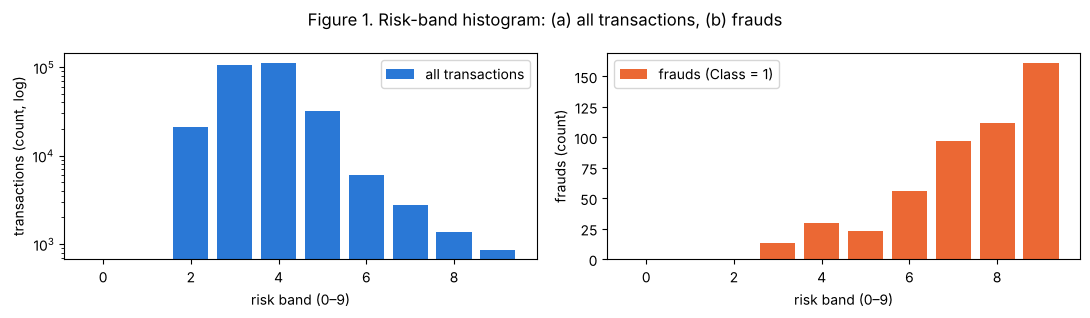

In [4]:
df = pd.read_csv(CSV)
N = len(df)
df["txn_id"] = np.arange(1, N + 1)
V = df[[f"V{i}" for i in range(1, 29)]].to_numpy()
z = (V - V.mean(axis=0)) / V.std(axis=0)
df["risk"] = (z ** 2).sum(axis=1)
df["band"] = np.clip(np.floor(np.log2(df["risk"])), 0, 9).astype(int)
df["cents"] = np.round(df["Amount"] * 100).astype(np.int64)
df["t"] = df["Time"].astype(np.int64)

A, T, NN = int(df.cents.max()) + 1, int(df.t.max()) + 1, N + 1
KEY = [(((9 - b) * A + (A - 1 - c)) * T + t) * NN + i          # exact packing, < 2^63
       for b, c, t, i in zip(df.band.tolist(), df.cents.tolist(), df.t.tolist(), df.txn_id.tolist())]
BKEY = [9 - b for b in df.band.tolist()]                          # C6: band only

bands = pd.DataFrame({"transactions": np.bincount(df.band, minlength=10),
                      "frauds": np.bincount(df.band[df.Class == 1], minlength=10)})
bands["fraud rate %"] = (100 * bands.frauds / bands.transactions.replace(0, np.nan)).round(3)
display(bands)
vc = df.cents.value_counts()
print("distinct Amounts:", len(vc), "| top-10 Amounts share: %.1f%%" % (100 * vc.head(10).sum() / N))
print("records sharing (band, Amount) with another:", int((df.groupby(["band", "cents"]).size() > 1).pipe(
      lambda s_: df.set_index(["band", "cents"]).index.isin(s_[s_].index)).sum()))
inv = count_inversions(KEY)
print("raw file vs triage key: %.2f%% of max inversions (50%% = random)" % (100 * inv / (N * (N - 1) / 2)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(bands.index, bands.transactions, color="#2a78d6", label="all transactions"); ax[0].set_yscale("log")
ax[0].set_xlabel("risk band (0–9)"); ax[0].set_ylabel("transactions (count, log)"); ax[0].legend()
ax[1].bar(bands.index, bands.frauds, color="#eb6834", label="frauds (Class = 1)")
ax[1].set_xlabel("risk band (0–9)"); ax[1].set_ylabel("frauds (count)"); ax[1].legend()
fig.suptitle("Figure 1. Risk-band histogram: (a) all transactions, (b) frauds"); plt.tight_layout(); plt.show()

## Prediction Log — 24i-2573 (s = 242573, K = 100)

Written BEFORE each round was run (after Problem A only). The "What happened /
what I got wrong" part is filled in after the run and never edits the prediction.

Things I knew going in: Insertion O(n) best / O(n²) worst, Merge always n log n,
Quick n log n average but n² on bad pivots, Heap n log n always. Problem A told me
the file is sorted by Time but that is ~50% inversions w.r.t. the triage key (basically
random), and the bands are very tie-heavy (bands 3+4 = 77% of rows).

## Round C1 — Arrival (file order)
- Winner: Naive Quick Sort. Arrival order looks random for our key (Problem A), and random input
  is exactly where last-element pivot is fine; quick sort is "fastest in practice" in class.
- Loser: Insertion Sort. ~n²/4 shifts; at 5.6M comps/s (my quick test) n=100k would be
  2.5e9 comps ≈ 450 s → DNF at 100k and 284,807.
- Heap vs Merge: I think Heap ≈ Merge because both are n log n and Heap needs no extra array.

## Round C2 — Shuffled
- Same as C1 (both random): Naive Quick wins, Hardened Quick a close 2nd (random pivot just costs
  one random number per partition), Insertion loses (DNF ≥ 100k).
- Merge Sort will make the FEWEST comparisons (≈ n lg n − n), Quick ≈ 1.39 n lg n.

## Round C3 — Pre-ranked
- Winner: Insertion Sort, exactly n−1 comparisons, O(n).
- Loser: Naive Quick Sort: last element is the max, every partition peels off 1 element →
  n²/2 comparisons → DNF at 100k.
- Heap Sort doesn't care about order, so same time as C2. Merge a bit faster than C2.

## Round C4 — Reverse-ranked
- Loser (tie): Insertion Sort (n²/2, worst case) and Naive Quick Sort (pivot = min every time).
  Both DNF at 100k.
- Winner: Merge Sort (it only does ~n/2 lg n comparisons on reversed data).

## Round C5 — Nearly ranked (1% displaced)
- Winner: Insertion Sort at ALL sizes — 99% is already in place so it is close to linear.
- Naive Quick Sort: the 1% random records break the sorted pattern, so I expect normal
  n log n behaviour, no DNF.

## Round C6 — Band-only key (C1 order, 8 distinct values)
- Everybody gets faster because there are only 8 different keys.
- Winner: Hardened Quick Sort (three-way partition puts each band in one pass).
- Naive Quick Sort: input is in C1 order (random) so it should be fine, similar to C2.
- Insertion still DNF at 100k (random order).

## Problem D — Shift queue
- Size-K heap wins for K ≥ 50; the buffer only wins at K = 10 (M5 crossover ≈ 16, see below).
- Full sort becomes the best method only around K = n/10.
- C1 vs C2 makes no difference (both random for this key).
- Fraud capture: band 9 alone has 161 frauds in 862 rows, band 8 has 112, so I guess half
  (246) are captured by K ≈ 1,000.

## Problem E — Live feed
- (b) size-K heap is fastest; (a) re-rank is slowest and gets ~6× worse with 10-min windows
  (6× more re-sorts). (c) is in the middle; window size barely matters for (b).

## Problem F predictions
- M5: buffer insert ≈ K/2 comparisons per replacement, heap ≈ 2 lg K → crossover K/2 = 2 lg K →
  K ≈ 16 (by comparisons).
- M6: Naive Quick on C6 comparisons ≈ Σ mᵢ(mᵢ−1)/2 over the band groups.

## Building the six input conditions

In [5]:
def sample_idx(n):
    if n >= N: return list(range(N))
    pick = np.zeros(N, dtype=bool)
    pick[random.Random(S).sample(range(N), n)] = True
    return list(np.flatnonzero(pick))                 # back in Time (file) order

def build(n, cond):
    idx = sample_idx(n)
    base = [KEY[i] for i in idx]
    if cond == "C1": return base                       # arrival (Time) order
    if cond == "C2":
        a = base[:]; random.Random(S).shuffle(a); return a
    if cond == "C6": return [BKEY[i] for i in idx]     # band-only key
    ranked = merge_sort(base)[0]                       # my own sort builds C3
    if cond == "C3": return ranked
    if cond == "C4": return ranked[::-1]
    if cond == "C5":                                   # move 1% to random positions
        r = random.Random(S); a = ranked[:]
        m = max(1, round(0.01 * len(a)))
        picked = set(r.sample(range(len(a)), m)); moved = [a[i] for i in sorted(picked)]
        a = [x for i, x in enumerate(a) if i not in picked]
        for x in moved: a.insert(r.randint(0, len(a)), x)
        return a

INPUTS = {(c, n): build(n, c) for n in SIZES for c in CONDITIONS}
print("built", len(INPUTS), "inputs")

built 12 inputs


## Problem C — the tournament
Fresh copy per run, `perf_counter`, median of the runs. A single run over 5 minutes raises DNF,
and larger n for that contender/condition are then recorded as DNF.

In [6]:
def timed(fn, base, reps):
    times, out, st = [], None, None
    for _ in range(reps):
        inp = list(base); t0 = perf_counter()
        try:
            out, st = fn(inp, t0 + DNF_SECONDS)
        except DNF:
            return None, None, None
        times.append(perf_counter() - t0)
    return statistics.median(times), out, st

rows = []
for cond in CONDITIONS:
    for name, f in SORTS.items():
        dead = False
        for n in SIZES:
            base = INPUTS[(cond, n)]
            if dead:
                rows.append(dict(cond=cond, algo=name, n=n, status="DNF")); continue
            t, out, st = timed(f, base, REPS)
            if t is None:
                dead = True; rows.append(dict(cond=cond, algo=name, n=n, status="DNF"))
            else:
                rows.append(dict(cond=cond, algo=name, n=n, status="ok", time=t, comps=st.comps,
                                 moves=st.moves, extra=st.peak_extra, correct=(out == sorted(base))))
            print(f"{cond} {name:20s} n={n:>7}: {rows[-1]['status']} {rows[-1].get('time', '')}")
C = pd.DataFrame(rows)
print("all completed runs identical to reference:", bool(C[C.status == "ok"].correct.all()))

C1 Insertion Sort       n=   1000: ok 0.028888813999969898


C1 Insertion Sort       n=  10000: ok 2.9384942749999254
C1 Merge Sort           n=   1000: ok 0.0018283840000776763
C1 Merge Sort           n=  10000: ok 0.031762587000002895
C1 Naive Quick Sort     n=   1000: ok 0.0024837989999468846


C1 Naive Quick Sort     n=  10000: ok 0.033756584000002476
C1 Hardened Quick Sort  n=   1000: ok 0.0044719920000488855
C1 Hardened Quick Sort  n=  10000: ok 0.036562129999992976
C1 Heap Sort            n=   1000: ok 0.0019492929999387343


C1 Heap Sort            n=  10000: ok 0.025940349000052265
C2 Insertion Sort       n=   1000: ok 0.02628005500002928


C2 Insertion Sort       n=  10000: ok 2.673797915000023
C2 Merge Sort           n=   1000: ok 0.0015775379999922734
C2 Merge Sort           n=  10000: ok 0.020289778000005754
C2 Naive Quick Sort     n=   1000: ok 0.001218923999999788
C2 Naive Quick Sort     n=  10000: ok 0.017786791000048652
C2 Hardened Quick Sort  n=   1000: ok 0.0028679739999688536


C2 Hardened Quick Sort  n=  10000: ok 0.034180483000000095
C2 Heap Sort            n=   1000: ok 0.0018871429999762768
C2 Heap Sort            n=  10000: ok 0.025400024000077792
C3 Insertion Sort       n=   1000: ok 0.00012756199998875672
C3 Insertion Sort       n=  10000: ok 0.0013830580001013004
C3 Merge Sort           n=   1000: ok 0.001010164999911467
C3 Merge Sort           n=  10000: ok 0.011663732000101845


... (6 outputs left out)

C5 Naive Quick Sort     n=  10000: ok 0.2796116600000005
C5 Hardened Quick Sort  n=   1000: ok 0.0029413500000146087
C5 Hardened Quick Sort  n=  10000: ok 0.034703992999993716
C5 Heap Sort            n=   1000: ok 0.0019951240000182224
C5 Heap Sort            n=  10000: ok 0.02613676199996462


C6 Insertion Sort       n=   1000: ok 0.016278532999990603


C6 Insertion Sort       n=  10000: ok 1.7770330140000397
C6 Merge Sort           n=   1000: ok 0.0013966550000077405
C6 Merge Sort           n=  10000: ok 0.017757875000029344
C6 Naive Quick Sort     n=   1000: ok 0.017334352000034414


C6 Naive Quick Sort     n=  10000: ok 1.7155732539999917
C6 Hardened Quick Sort  n=   1000: ok 0.00027773899989824713
C6 Hardened Quick Sort  n=  10000: ok 0.003210099999932936
C6 Heap Sort            n=   1000: ok 0.0013985809999894627
C6 Heap Sort            n=  10000: ok 0.019137848000013946
all completed runs identical to reference: True


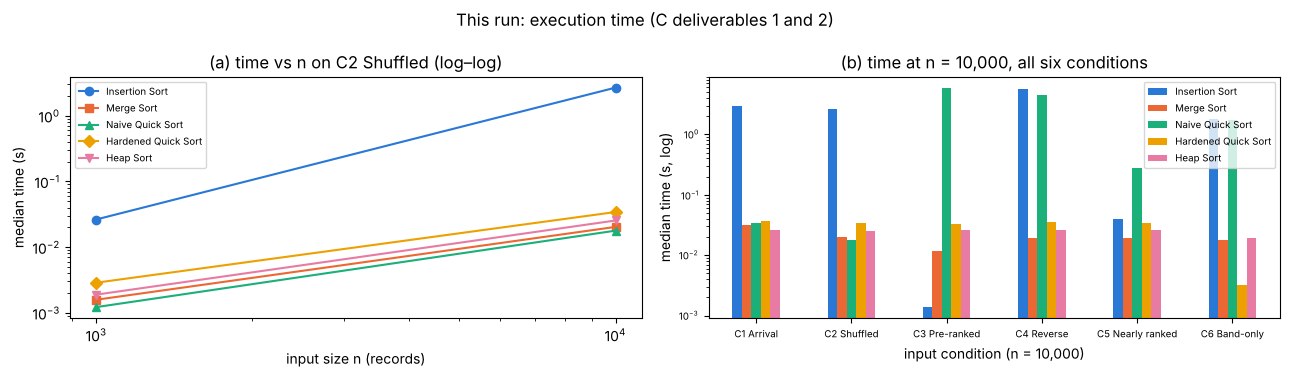

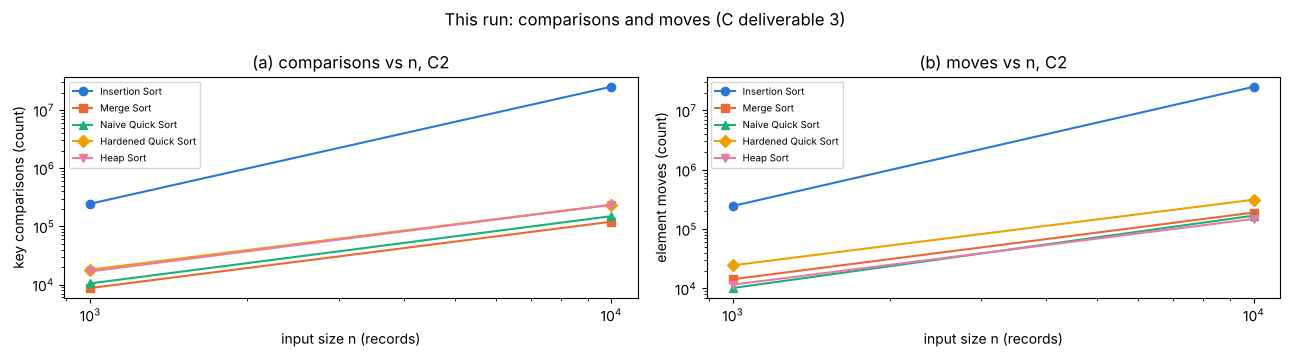

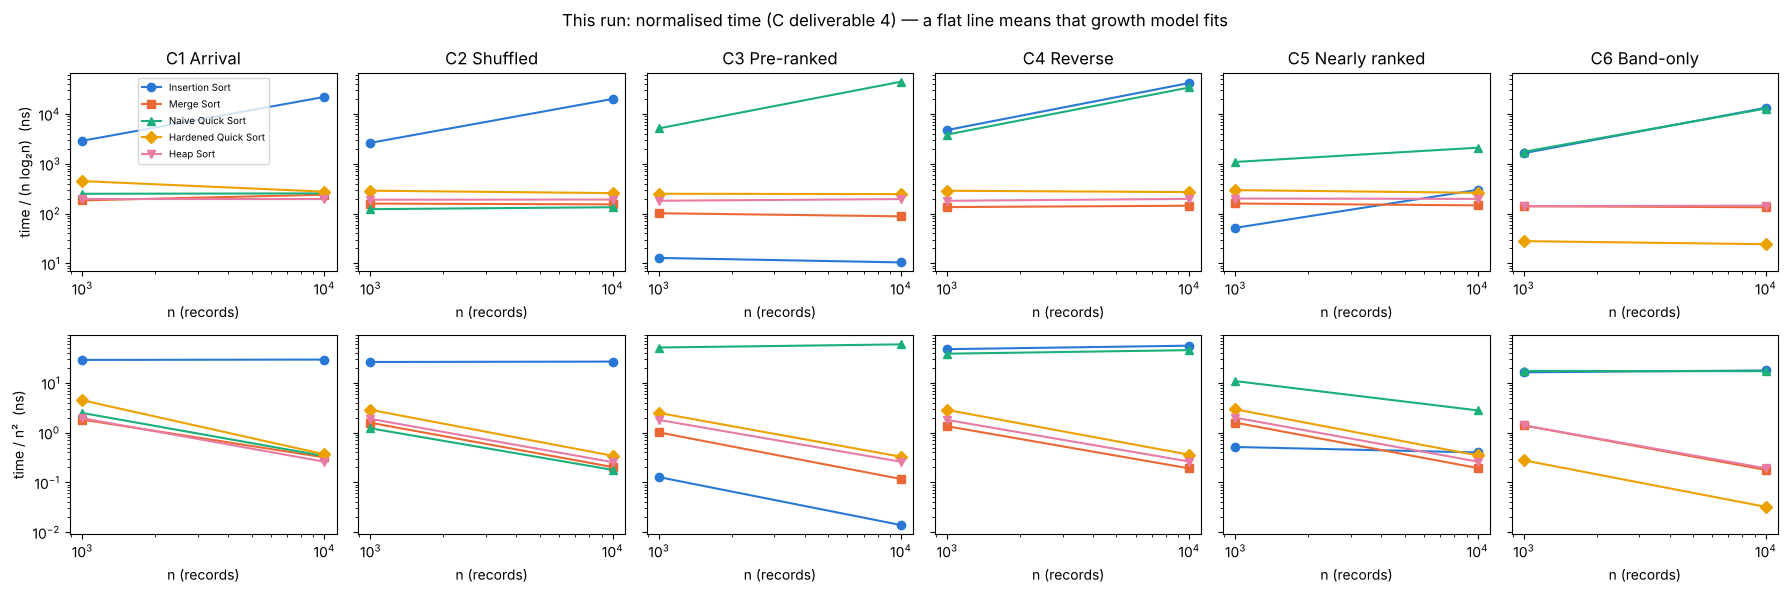

This run: summary table (C deliverable 5)


time n=1,000 (s) time n=10,000 (s)  counts at n  \
cond algo                                                                  
C1   Hardened Quick Sort           0.0045            0.0366        10000   
     Heap Sort                     0.0019            0.0259        10000   
     Insertion Sort                0.0289            2.9385        10000   
     Merge Sort                    0.0018            0.0318        10000   
     Naive Quick Sort              0.0025            0.0338        10000   
C2   Hardened Quick Sort           0.0029            0.0342        10000   
     Heap Sort                     0.0019            0.0254        10000   
     Insertion Sort                0.0263            2.6738        10000   
     Merge Sort                    0.0016            0.0203        10000   
     Naive Quick Sort              0.0012            0.0178        10000   
C3   Hardened Quick Sort           0.0025            0.0327        10000   
     Heap Sort                     0.0018            0.0259        10000   
     Insertion Sort                0.0001            0.0014        10000   
     Merge Sort                    0.0010            0.0117        10000   
     Naive Quick Sort              0.0513            5.9403        10000   
C4   Hardened Quick Sort           0.0029            0.0358        10000   
     Heap Sort                     0.0018            0.0262        10000   
     Insertion Sort                0.0475            5.5910        10000   
     Merge Sort                    0.0013            0.0191        10000   
     Naive Quick Sort              0.0386            4.5466        10000   
C5   Hardened Quick Sort           0.0029            0.0347        10000   
     Heap Sort                     0.0020            0.0261        10000   
     Insertion Sort                0.0005            0.0398        10000   
     Merge Sort                    0.0016            0.0194        10000   
     Naive Quick Sort              0.0108            0.2796        10000   
C6   Hardened Quick Sort           0.0003            0.0032        10000   
     Heap Sort                     0.0014            0.0191        10000   
     Insertion Sort                0.0163            1.7770        10000   
     Merge Sort                    0.0014            0.0178        10000   
     Naive Quick Sort              0.0173            1.7156        10000   

                          comparisons      moves  extra slots stable  
cond algo                                                             
C1   Hardened Quick Sort       248925     327588           10     no  
     Heap Sort                 235403     149054            0     no  
     Insertion Sort          24613346   24613357            0    yes  
     Merge Sort                120223     190294         5001    yes  
     Naive Quick Sort          161951     191746            9     no  
C2   Hardened Quick Sort       235805     313528           10     no  
     Heap Sort                 235414     149154            0     no  
     Insertion Sort          25160617   25160627            0    yes  
     Merge Sort                120454     190531         5001    yes  
     Naive Quick Sort          149955     169116           10     no  
C3   Hardened Quick Sort       227596     303514           10     no  
     Heap Sort                 244460     156954            0     no  
     Insertion Sort              9999       9999            0    yes  
     Merge Sort                 64608     129216         5001    yes  
     Naive Quick Sort        49995000  100009998            2     no  
C4   Hardened Quick Sort       237013     305500           10     no  
     Heap Sort                 226682     141694            0     no  
     Insertion Sort          49995000   50004999            0    yes  
     Merge Sort                 69008     198224         5001    yes  
     Naive Quick Sort        49995000   50009998            2     no  
C5   Hardened Quick Sort      

In [7]:
# ---------- plotting helpers (used for this run AND for the saved full-size run at the end)
ALGOS = list(SORTS)
COL = dict(zip(ALGOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MRK = dict(zip(ALGOS, "os^Dv"))
COND_NAME = {"C1": "C1 Arrival", "C2": "C2 Shuffled", "C3": "C3 Pre-ranked", "C4": "C4 Reverse",
             "C5": "C5 Nearly ranked", "C6": "C6 Band-only"}

def plot_C(Cdf, tag):
    ok = Cdf[Cdf.status == "ok"]
    # Figure: time vs n on C2 (log-log) + grouped bars at n = 10,000
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    for a in ALGOS:
        d = Cdf[(Cdf.algo == a) & (Cdf.cond == "C2")]
        g = d[d.status == "ok"]
        ax[0].plot(g.n, g.time, marker=MRK[a], color=COL[a], label=a)
        x = d[d.status == "DNF"]
        if len(x): ax[0].scatter(x.n, [DNF_SECONDS] * len(x), marker="x", s=50, color=COL[a])
    if (Cdf.status == "DNF").any():
        ax[0].axhline(DNF_SECONDS, ls=":", color="grey", label="DNF limit 300 s (x = DNF)")
    ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].legend(fontsize=7)
    ax[0].set_xlabel("input size n (records)"); ax[0].set_ylabel("median time (s)")
    ax[0].set_title("(a) time vs n on C2 Shuffled (log–log)")
    piv = ok[ok.n == 10_000].pivot(index="cond", columns="algo", values="time").reindex(columns=ALGOS)
    piv.index = [COND_NAME[c] for c in piv.index]
    piv.plot.bar(ax=ax[1], logy=True, color=[COL[a] for a in ALGOS], rot=0, fontsize=7)
    ax[1].set_xlabel("input condition (n = 10,000)"); ax[1].set_ylabel("median time (s, log)")
    ax[1].set_title("(b) time at n = 10,000, all six conditions"); ax[1].legend(fontsize=7)
    fig.suptitle(f"{tag}: execution time (C deliverables 1 and 2)"); plt.tight_layout(); plt.show()

    # Figure: comparisons and moves vs n on C2
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    for a in ALGOS:
        d = ok[(ok.algo == a) & (ok.cond == "C2")]
        ax[0].plot(d.n, d.comps, marker=MRK[a], color=COL[a], label=a)
        ax[1].plot(d.n, d.moves, marker=MRK[a], color=COL[a], label=a)
    for k, t_, y in ((0, "(a) comparisons vs n, C2", "key comparisons (count)"), (1, "(b) moves vs n, C2", "element moves (count)")):
        ax[k].set_xscale("log"); ax[k].set_yscale("log"); ax[k].set_title(t_)
        ax[k].set_xlabel("input size n (records)"); ax[k].set_ylabel(y); ax[k].legend(fontsize=7)
    fig.suptitle(f"{tag}: comparisons and moves (C deliverable 3)"); plt.tight_layout(); plt.show()

    # Figure: time/(n log n) and time/n^2 vs n, every contender, every condition
    fig, ax = plt.subplots(2, 6, figsize=(18, 6), sharey="row")
    for j, c in enumerate(CONDITIONS):
        for a in ALGOS:
            d = ok[(ok.algo == a) & (ok.cond == c)]
            ax[0][j].plot(d.n, d.time / (d.n * np.log2(d.n)) * 1e9, marker=MRK[a], color=COL[a], label=a)
            ax[1][j].plot(d.n, d.time / d.n.astype(float) ** 2 * 1e9, marker=MRK[a], color=COL[a], label=a)
        for r in (0, 1):
            ax[r][j].set_xscale("log"); ax[r][j].set_yscale("log"); ax[r][j].set_xlabel("n (records)")
        ax[0][j].set_title(COND_NAME[c])
    ax[0][0].set_ylabel("time / (n log₂n)  (ns)"); ax[1][0].set_ylabel("time / n²  (ns)")
    ax[0][0].legend(fontsize=7)
    fig.suptitle(f"{tag}: normalised time (C deliverable 4) — a flat line means that growth model fits")
    plt.tight_layout(); plt.show()

    # Table: time, comparisons, moves, extra memory, stability (C deliverable 5)
    t = Cdf[Cdf.algo.isin(ALGOS)].copy()
    t["cell"] = [f"{x:.4f}" if st == "ok" else "DNF" for x, st in zip(t.time, t.status)]
    tab = t.pivot_table(index=["cond", "algo"], columns="n", values="cell", aggfunc="first")
    tab.columns = [f"time n={c:,} (s)" for c in tab.columns]
    last = ok[ok.algo.isin(ALGOS)].sort_values("n").groupby(["cond", "algo"]).last()[["n", "comps", "moves", "extra"]]
    last.columns = ["counts at n", "comparisons", "moves", "extra slots"]
    tab = tab.join(last)
    tab["stable"] = ["yes" if a in ("Insertion Sort", "Merge Sort") else "no" for _, a in tab.index]
    print(f"{tag}: summary table (C deliverable 5)"); display(tab)

plot_C(C, "This run")

## Problem D — the shift queue (top-K)

all correct: True


frauds in my top K=100: 0 | smallest K capturing half the frauds: 2,068


  cost of the half-frauds queue (K=2,068, n=284,807, C1) with Full sort (Merge Sort) + first K: 0.765 s
  cost of the half-frauds queue (K=2,068, n=284,807, C1) with size-K heap                     : 0.046 s


  cost of the half-frauds queue (K=2,068, n=284,807, C1) with bounded insertion buffer        : 1.364 s


  cost of the half-frauds queue (K=2,068, n=284,807, C2) with Full sort (Merge Sort) + first K: 0.855 s
  cost of the half-frauds queue (K=2,068, n=284,807, C2) with size-K heap                     : 0.057 s


  cost of the half-frauds queue (K=2,068, n=284,807, C2) with bounded insertion buffer        : 1.384 s


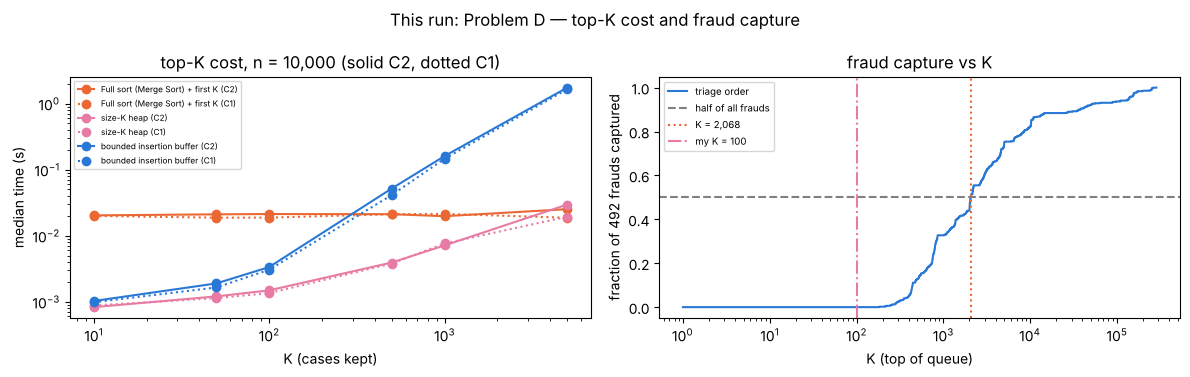

This run: median time (s) per method


method           Full sort (Merge Sort) + first K  bounded insertion buffer  \
n     cond K                                                                  
10000 C1   10                            0.019911                  0.000979   
           50                            0.018720                  0.001642   
           100                           0.018755                  0.003045   
           500                           0.021064                  0.041248   
           1000                          0.021361                  0.146070   
           5000                          0.018658                  1.644478   
      C2   10                            0.020268                  0.001024   
           50                            0.021012                  0.001889   
           100                           0.021234                  0.003343   
           500                           0.021128                  0.051719   
           1000                          0.019702                  0.160155   
           5000                          0.025155                  1.742655   

method           size-K heap  
n     cond K                  
10000 C1   10       0.000875  
           50       0.001132  
           100      0.001346  
           500      0.003777  
           1000     0.007606  
           5000     0.019306  
      C2   10       0.000827  
           50       0.001202  
           100      0.001483  
           500      0.003918  
           1000     0.007107  
           5000     0.029530

In [8]:
METHODS = {"Full sort (Merge Sort) + first K": lambda a, k, d: (lambda r: (r[0][:k], r[1]))(merge_sort(a, deadline=d)),
           "size-K heap": lambda a, k, d: topk_heap(a, k, deadline=d),
           "bounded insertion buffer": lambda a, k, d: topk_buffer(a, k, deadline=d)}
drows = []
for n in D_SIZES:
    for cond in ("C1", "C2"):
        base = INPUTS[(cond, n)] if (cond, n) in INPUTS else build(n, cond)
        for k in [10, 50, K, 500, 5000, n // 10]:
            want = sorted(base)[:k]
            for m, f in METHODS.items():
                t, out, st = timed(lambda a, d: f(a, k, d), base, REPS)
                drows.append(dict(n=n, cond=cond, K=k, method=m, time=t, comps=st.comps if st else None,
                                  correct=(out == want) if out is not None else None))
Dres = pd.DataFrame(drows)
print("all correct:", bool(Dres.correct.dropna().all()))

order = merge_sort(KEY)[0]
cls = dict(zip(KEY, df.Class))
curve = np.cumsum([cls[k] for k in order]); total = int(df.Class.sum())
half_K = int(np.argmax(curve * 2 >= total)) + 1
print(f"frauds in my top K={K}: {curve[K - 1]} | smallest K capturing half the frauds: {half_K:,}")
full_c1, full_c2 = KEY, build(N, "C2")
for cond, base in (("C1", full_c1), ("C2", full_c2)):
    for m, f in METHODS.items():
        t, out, _ = timed(lambda a, d: f(a, half_K, d), base, REPS)
        print(f"  cost of the half-frauds queue (K={half_K:,}, n={N:,}, {cond}) with {m:32s}: "
              + (f"{t:.3f} s" if t is not None else "DNF"))

DCOL = {"Full sort (Merge Sort) + first K": "#eb6834", "size-K heap": "#e87ba4", "bounded insertion buffer": "#2a78d6"}

def plot_D(Ddf, sizes, tag):
    fig, ax = plt.subplots(1, len(sizes) + 1, figsize=(6 * (len(sizes) + 1), 3.8))
    for i, n in enumerate(sizes):
        for m, c in DCOL.items():
            for cond, ls in (("C2", "-"), ("C1", ":")):
                d = Ddf[(Ddf.method == m) & (Ddf.cond == cond) & (Ddf.n == n)].dropna(subset=["time"]).sort_values("K")
                ax[i].plot(d.K, d.time, marker="o", ls=ls, color=c, label=f"{m} ({cond})")
        ax[i].set_xscale("log"); ax[i].set_yscale("log"); ax[i].set_xlabel("K (cases kept)")
        ax[i].set_ylabel("median time (s)"); ax[i].set_title(f"top-K cost, n = {n:,} (solid C2, dotted C1)")
        ax[i].legend(fontsize=6)
    ax[-1].plot(np.arange(1, N + 1), curve / total, color="#2a78d6", label="triage order")
    ax[-1].axhline(0.5, ls="--", color="grey", label="half of all frauds")
    ax[-1].axvline(half_K, ls=":", color="#eb6834", label=f"K = {half_K:,}")
    ax[-1].axvline(K, ls="-.", color="#e87ba4", label=f"my K = {K}")
    ax[-1].set_xscale("log"); ax[-1].set_xlabel("K (top of queue)"); ax[-1].set_ylabel("fraction of 492 frauds captured")
    ax[-1].set_title("fraud capture vs K"); ax[-1].legend(fontsize=7)
    fig.suptitle(f"{tag}: Problem D — top-K cost and fraud capture"); plt.tight_layout(); plt.show()
    print(f"{tag}: median time (s) per method"); display(Ddf.pivot_table(index=["n", "cond", "K"], columns="method", values="time"))

plot_D(Dres, D_SIZES, "This run")

## Problem E — the live feed (publish the top K after every window)

 60-min windows | (a) re-rank everything         total   16.095 s | peak extra 712,018 slots | final top-K correct: True
 60-min windows | (b) size-K heap                total    0.024 s | peak extra 200 slots | final top-K correct: True


 60-min windows | (c) merge sort window + merge  total    0.690 s | peak extra 15,043 slots | final top-K correct: True


 10-min windows | (a) re-rank everything         total   94.741 s | peak extra 712,018 slots | final top-K correct: True
 10-min windows | (b) size-K heap                total    0.050 s | peak extra 200 slots | final top-K correct: True


 10-min windows | (c) merge sort window + merge  total    0.874 s | peak extra 3,529 slots | final top-K correct: True


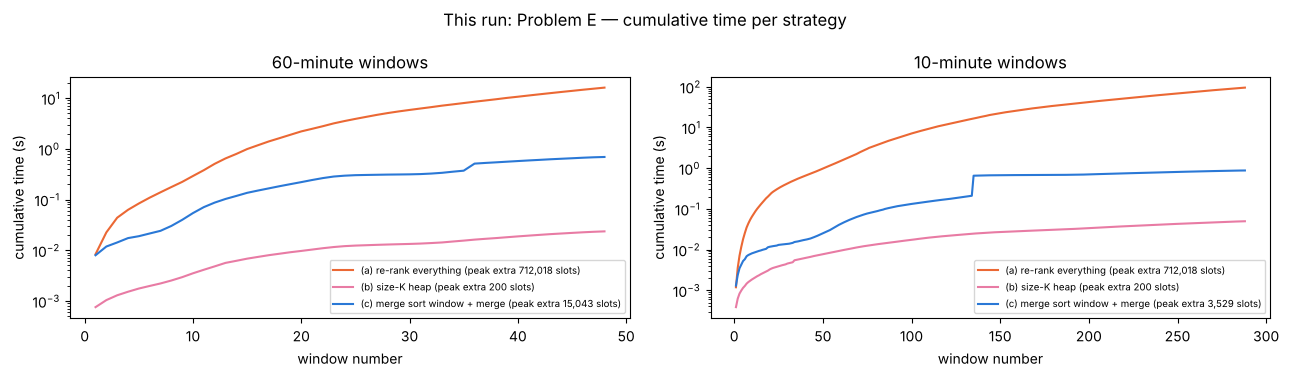

In [9]:
def windows(w):
    wins, cur, edge = [], [], w
    for k, t in zip(KEY, df.t.tolist()):
        while t >= edge: wins.append(cur); cur = []; edge += w
        cur.append(k)
    wins.append(cur); return wins

def strategy(name, wins):
    per, peak = [], 0
    if name == "(a) re-rank everything":
        seen = []
        for w in wins:
            t0 = perf_counter(); seen.extend(w); r, st = merge_sort(seen); top = r[:K]
            per.append(perf_counter() - t0); peak = max(peak, len(seen) + st.peak_extra + len(r))
    elif name == "(b) size-K heap":
        h = LiveHeap(K)
        for w in wins:
            t0 = perf_counter(); h.feed(w); top = h.publish(); per.append(perf_counter() - t0)
            peak = max(peak, K + len(top))
    else:
        top = []
        for w in wins:
            t0 = perf_counter(); ws, st = merge_sort(w); top, _ = merge_topk(top, ws, K)
            per.append(perf_counter() - t0); peak = max(peak, len(ws) + st.peak_extra + 2 * K)
    return per, peak, top

STRATS = ["(a) re-rank everything", "(b) size-K heap", "(c) merge sort window + merge"]
ECOL = dict(zip(STRATS, ["#eb6834", "#e87ba4", "#2a78d6"]))

def plot_E(curves, tag):
    ws = sorted({c["window_s"] for c in curves}, reverse=True)
    fig, ax = plt.subplots(1, len(ws), figsize=(6.5 * len(ws), 3.8), squeeze=False)
    for j, w in enumerate(ws):
        for c in curves:
            if c["window_s"] != w: continue
            ax[0][j].plot(np.arange(1, len(c["cum"]) + 1), c["cum"], color=ECOL[c["algo"]],
                          label=f"{c['algo']} (peak extra {c['peak']:,} slots)")
        ax[0][j].set_yscale("log"); ax[0][j].set_xlabel("window number"); ax[0][j].set_ylabel("cumulative time (s)")
        ax[0][j].set_title(f"{w // 60}-minute windows"); ax[0][j].legend(fontsize=7)
    fig.suptitle(f"{tag}: Problem E — cumulative time per strategy"); plt.tight_layout(); plt.show()

Ecurves = []
for w in E_WINDOWS:
    wins = windows(w)
    for s_name in STRATS:
        runs = [strategy(s_name, wins) for _ in range(E_REPS)]
        cum = list(np.median([np.cumsum(r[0]) for r in runs], axis=0))
        Ecurves.append(dict(window_s=w, algo=s_name, peak=runs[0][1], cum=cum))
        print(f"{w // 60:>3}-min windows | {s_name:30s} total {cum[-1]:8.3f} s | peak extra {runs[0][1]:,} slots"
              f" | final top-K correct: {runs[0][2] == sorted(KEY)[:K]}")
plot_E(Ecurves, "This run")

## Full-size results (QUICK = False run: n up to 284,807, median of 5)
These are the measurements behind my report (`results.csv`), produced by running this same code with `QUICK = False`.
They are embedded here so the full-size graphs show instantly; re-running with `QUICK = False` regenerates them (takes hours).

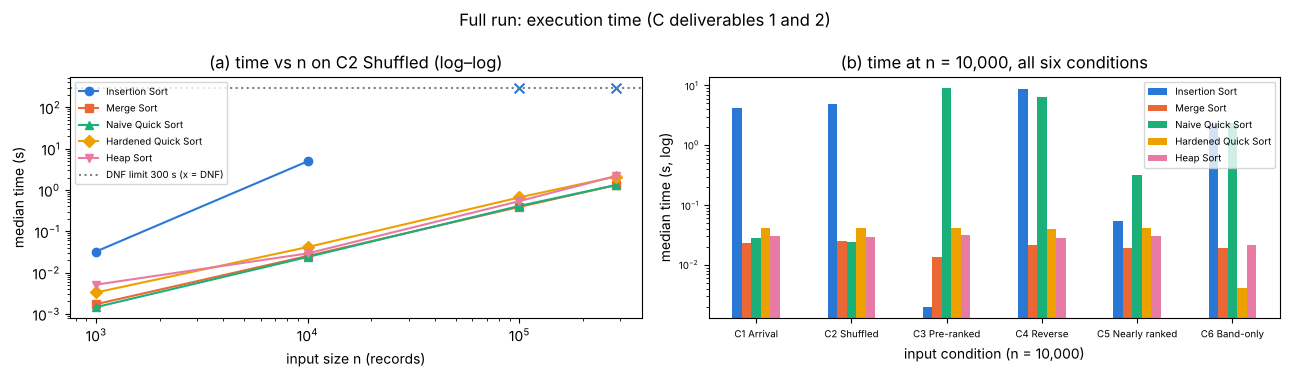

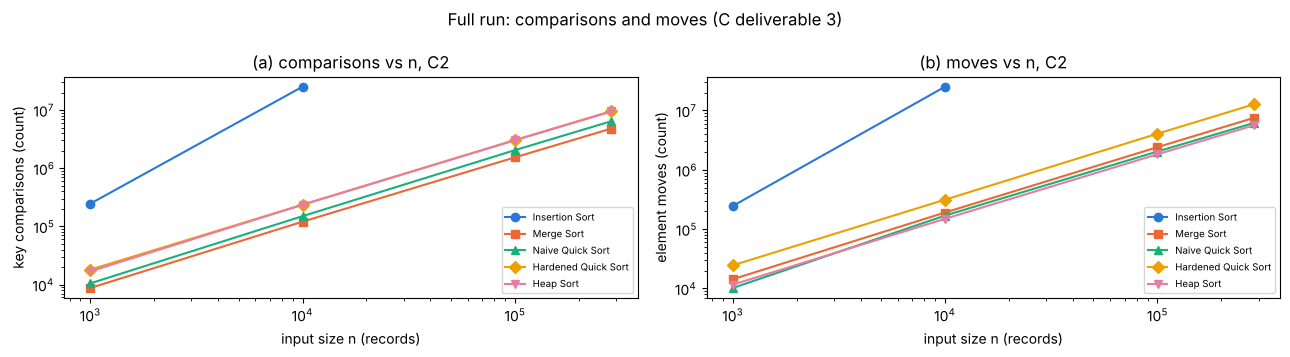

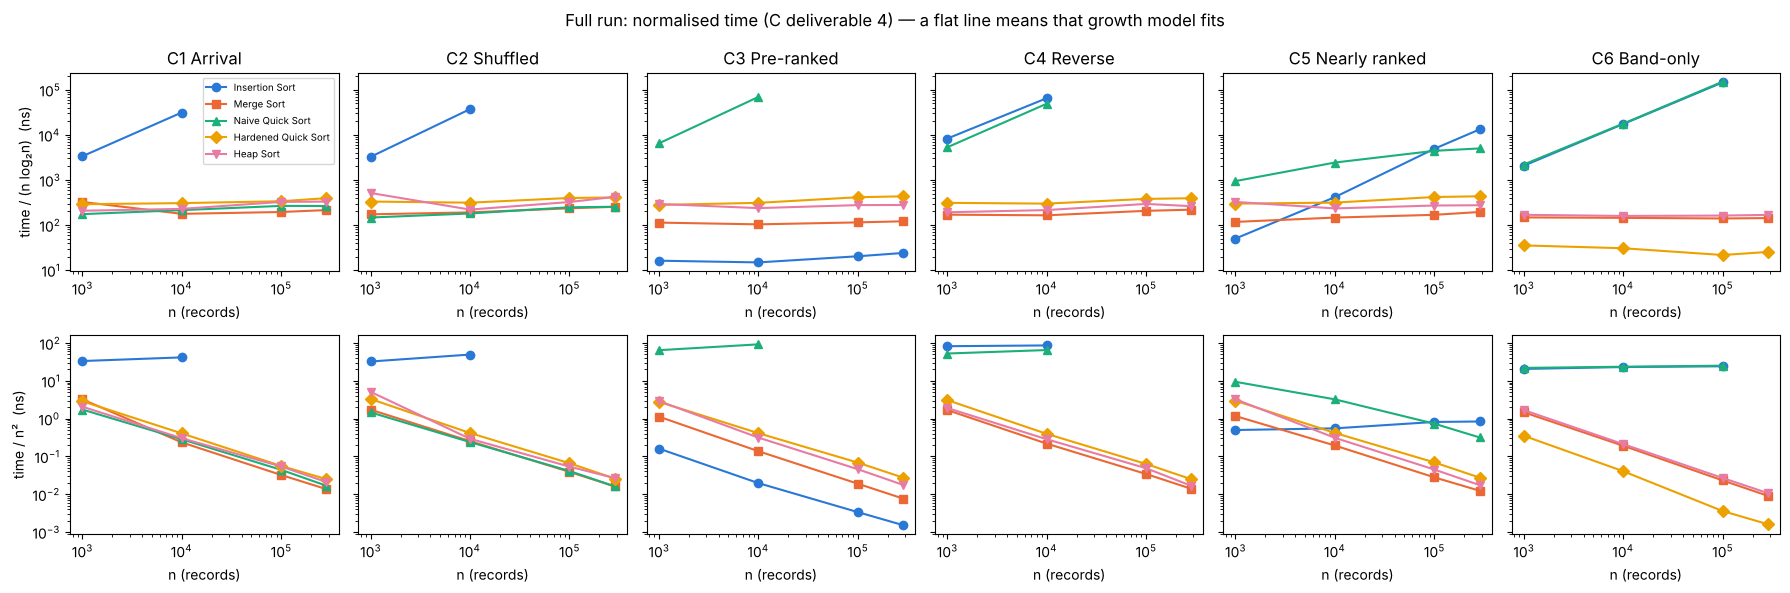

Full run: summary table (C deliverable 5)


time n=1,000 (s) time n=10,000 (s)  \
cond algo                                                     
C1   Hardened Quick Sort           0.0029            0.0406   
     Heap Sort                     0.0021            0.0303   
     Insertion Sort                0.0333            4.1601   
     Merge Sort                    0.0032            0.0235   
     Naive Quick Sort              0.0017            0.0284   
C2   Hardened Quick Sort           0.0033            0.0416   
     Heap Sort                     0.0051            0.0292   
     Insertion Sort                0.0324            4.9410   
     Merge Sort                    0.0017            0.0253   
     Naive Quick Sort              0.0015            0.0239   
C3   Hardened Quick Sort           0.0028            0.0412   
     Heap Sort                     0.0029            0.0315   
     Insertion Sort                0.0002            0.0020   
     Merge Sort                    0.0011            0.0137   
     Naive Quick Sort              0.0645            9.2002   
C4   Hardened Quick Sort           0.0031            0.0396   
     Heap Sort                     0.0019            0.0285   
     Insertion Sort                0.0823            8.6178   
     Merge Sort                    0.0017            0.0218   
     Naive Quick Sort              0.0526            6.5039   
C5   Hardened Quick Sort           0.0030            0.0417   
     Heap Sort                     0.0032            0.0310   
     Insertion Sort                0.0005            0.0552   
     Merge Sort                    0.0012            0.0194   
     Naive Quick Sort              0.0094            0.3229   
C6   Hardened Quick Sort           0.0004            0.0041   
     Heap Sort                     0.0017            0.0211   
     Insertion Sort                0.0206            2.3105   
     Merge Sort                    0.0015            0.0191   
     Naive Quick Sort              0.0219            2.3539   

                         time n=100,000 (s) time n=284,807 (s)  counts at n  \
cond algo                                                                     
C1   Hardened Quick Sort             0.5592             2.0350       284807   
     Heap Sort                       0.5406             1.7062       284807   
     Insertion Sort                     DNF                DNF        10000   
     Merge Sort                      0.3229             1.1058       284807   
     Naive Quick Sort                0.4412             1.3621       284807   
C2   Hardened Quick Sort             0.6603             2.1085       284807   
     Heap Sort                       0.5370             2.1708       284807   
     Insertion Sort                     DNF                DNF        10000   
     Merge Sort                      0.3898             1.3055       284807   
     Naive Quick Sort                0.4108             1.3106       284807   
C3   Hardened Quick Sort             0.6865             2.2363       284807   
     Heap Sort                       0.4591             1.4355       284807   
     Insertion Sort                  0.0336             0.1237       284807   
     Merge Sort                      0.1899             0.6236       284807   
     Naive Quick Sort                   DNF                DNF        10000   
C4   Hardened Quick Sort             0.6308             2.0255       284807   
     Heap Sort                       0.4874             1.3531       284807   
     Insertion Sort                     DNF                DNF        10000   
     Merge Sort                      0.3426             1.1290       284807   
     Naive Quick Sort                   DNF                DNF        10000   
C5   Hardened Quick Sort             0.6939             2.2375       284807   
     Heap Sort                       0.4497             1.4169       284807   
     Insertion Sort                  8.1462            68.0049       284807   
     Merge Sort                  

DNF cells and their predicted times


,cond,algo,n,largest_finished_n,predicted_time_s
0,C1,Insertion Sort,100000,10000,416
1,C1,Insertion Sort,284807,10000,3374
2,C2,Insertion Sort,100000,10000,494
3,C2,Insertion Sort,284807,10000,4008
4,C3,Naive Quick Sort,100000,10000,920
5,C3,Naive Quick Sort,284807,10000,7463
6,C4,Insertion Sort,100000,10000,862
7,C4,Insertion Sort,284807,10000,6990
8,C4,Naive Quick Sort,100000,10000,650
9,C4,Naive Quick Sort,284807,10000,5276


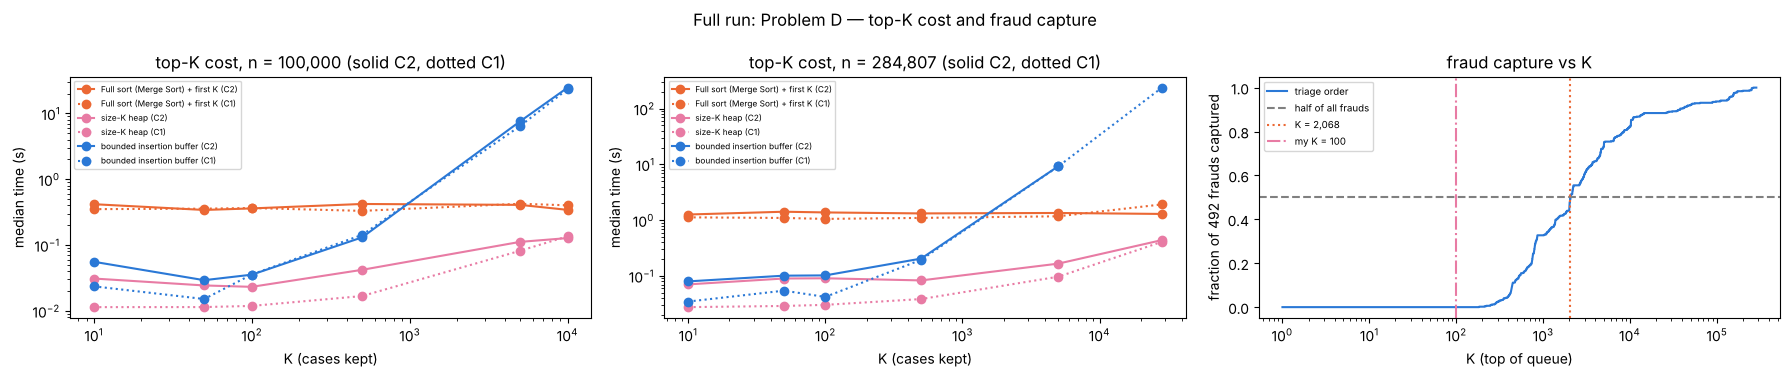

Full run: median time (s) per method


method               Full sort (Merge Sort) + first K  \
n      cond K                                           
100000 C1   10.0                             0.351202   
            50.0                             0.357159   
            100.0                            0.365306   
            500.0                            0.330611   
            5000.0                           0.423908   
            10000.0                          0.401393   
       C2   10.0                             0.417536   
            50.0                             0.341305   
            100.0                            0.360232   
            500.0                            0.420725   
            5000.0                           0.407744   
            10000.0                          0.342302   
284807 C1   10.0                             1.121657   
            50.0                             1.093630   
            100.0                            1.051993   
            500.0                            1.095805   
            5000.0                           1.171683   
            28480.0                          1.913124   
       C2   10.0                             1.260373   
            50.0                             1.414759   
            100.0                            1.373623   
            500.0                            1.318895   
            5000.0                           1.343372   
            28480.0                          1.290552   

method               bounded insertion buffer  size-K heap  
n      cond K                                               
100000 C1   10.0                     0.023617     0.011404  
            50.0                     0.015142     0.011429  
            100.0                    0.035701     0.011902  
            500.0                    0.142735     0.016811  
            5000.0                   6.422693     0.081852  
            10000.0                 23.391176     0.136041  
       C2   10.0                     0.055759     0.031020  
            50.0                     0.029266     0.024346  
            100.0                    0.035485     0.023194  
            500.0                    0.130890     0.042059  
            5000.0                   7.567448     0.111758  
            10000.0                 24.621087     0.127671  
284807 C1   10.0                     0.034701     0.027573  
            50.0                     0.054429     0.028943  
            100.0                    0.042018     0.030296  
            500.0                    0.194570     0.038485  
            5000.0                   9.193448     0.096778  
            28480.0                237.056530     0.408748  
       C2   10.0                     0.079787     0.070503  
            50.0                     0.101037     0.089889  
            100.0                    0.102160     0.090723  
            500.0                    0.204486     0.083064  
            5000.0                   9.253434     0.166122  
            28480.0                       NaN     0.438857

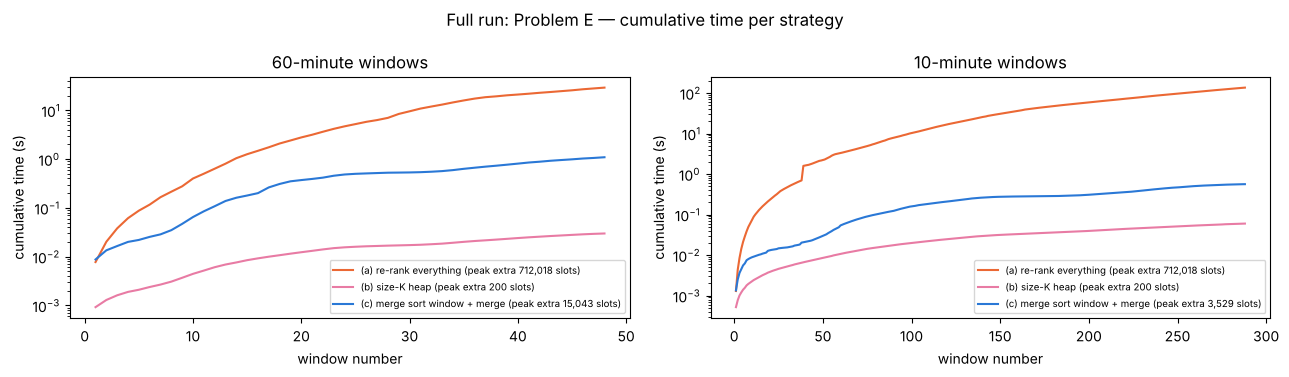

In [10]:
import io, json
FULL_C = pd.read_csv(io.StringIO("""cond,n,algo,status,time,comps,moves,extra
C1,1000,Insertion Sort,ok,0.0333176409999964,249375.0,249383.0,0.0
C2,1000,Insertion Sort,ok,0.0323909720000301,244878.0,244893.0,0.0
C1,10000,Insertion Sort,ok,4.160093633000031,24613346.0,24613357.0,0.0
C2,10000,Insertion Sort,ok,4.940969037999992,25160617.0,25160627.0,0.0
C1,100000,Insertion Sort,DNF,,,,
C1,284807,Insertion Sort,DNF,,,,
C3,1000,Insertion Sort,ok,0.0001610110000456,999.0,999.0,0.0
C3,10000,Insertion Sort,ok,0.0019681029999674,9999.0,9999.0,0.0
C3,100000,Insertion Sort,ok,0.0336253319999286,99999.0,99999.0,0.0
C2,100000,Insertion Sort,DNF,,,,
C2,284807,Insertion Sort,DNF,,,,
C4,1000,Insertion Sort,ok,0.0822600970000166,499500.0,500499.0,0.0
C3,284807,Insertion Sort,ok,0.1236855230000628,284806.0,284806.0,0.0
C5,1000,Insertion Sort,ok,0.0004985399999668,3528.0,3528.0,0.0
C5,10000,Insertion Sort,ok,0.0552171400000816,355268.0,355268.0,0.0
C5,100000,Insertion Sort,ok,8.146169020999992,33361299.0,33361299.0,0.0
C4,10000,Insertion Sort,ok,8.617798359999938,49995000.0,50004999.0,0.0
C4,100000,Insertion Sort,DNF,,,,
C4,284807,Insertion Sort,DNF,,,,
C6,1000,Insertion Sort,ok,0.020586226999967,172374.0,172377.0,0.0
C6,10000,Insertion Sort,ok,2.310456975000079,17060452.0,17060455.0,0.0
C5,284807,Insertion Sort,ok,68.004909978,276394325.0,276394325.0,0.0
C1,1000,Naive Quick Sort,ok,0.0017360710000957,11547.0,14570.0,7.0
C1,10000,Naive Quick Sort,ok,0.0283946829999877,161951.0,191746.0,9.0
C1,100000,Naive Quick Sort,ok,0.4411905350000324,1974406.0,2132808.0,12.0
C1,284807,Naive Quick Sort,ok,1.3620500039999115,6601882.0,7244210.0,13.0
C2,1000,Naive Quick Sort,ok,0.0014608339999995,10473.0,10150.0,7.0
C2,10000,Naive Quick Sort,ok,0.023928794999847,149955.0,169116.0,10.0
C2,100000,Naive Quick Sort,ok,0.4108329419998426,2042432.0,2032894.0,12.0
C2,284807,Naive Quick Sort,ok,1.3106395869999687,6436413.0,6162266.0,13.0
C3,1000,Naive Quick Sort,ok,0.0644737689999601,499500.0,1000998.0,2.0
C3,10000,Naive Quick Sort,ok,9.200190351000174,49995000.0,100009998.0,2.0
C3,100000,Naive Quick Sort,DNF,,,,
C3,284807,Naive Quick Sort,DNF,,,,
C4,1000,Naive Quick Sort,ok,0.0526388850000785,499500.0,500998.0,2.0
C4,10000,Naive Quick Sort,ok,6.503909864999969,49995000.0,50009998.0,2.0
C4,100000,Naive Quick Sort,DNF,,,,
C4,284807,Naive Quick Sort,DNF,,,,
C5,1000,Naive Quick Sort,ok,0.0093997629999194,100738.0,84950.0,5.0
C5,10000,Naive Quick Sort,ok,0.3228920430001381,2531317.0,799766.0,6.0
C5,100000,Naive Quick Sort,ok,7.344578973000125,35073272.0,34399024.0,8.0
C5,284807,Naive Quick Sort,ok,25.79336629799991,108198115.0,142968454.0,8.0
C6,1000,Naive Quick Sort,ok,0.0219187860000147,165488.0,330994.0,6.0
C6,10000,Naive Quick Sort,ok,2.3538544749999346,16002778.0,32001696.0,5.0
C6,100000,Insertion Sort,ok,242.03796221799985,1737639823.0,1737639828.0,0.0
C6,284807,Insertion Sort,DNF,,,,
C1,1000,Merge Sort,ok,0.003240870999889,8671.0,14235.0,501.0
C1,10000,Merge Sort,ok,0.0235155800000939,120223.0,190294.0,5001.0
C1,100000,Merge Sort,ok,0.3228761830000621,1531980.0,2402489.0,50001.0
C1,284807,Merge Sort,ok,1.105771685000036,4792310.0,7498997.0,142404.0
C2,1000,Merge Sort,ok,0.0017206879997502,8718.0,14268.0,501.0
C2,10000,Merge Sort,ok,0.0253149019999909,120454.0,190531.0,5001.0
C2,100000,Merge Sort,ok,0.389787017999879,1536322.0,2406684.0,50001.0
C2,284807,Merge Sort,ok,1.3054938570003287,4804255.0,7510988.0,142404.0
C3,1000,Merge Sort,ok,0.0011269829997218,4932.0,9864.0,501.0
C3,10000,Merge Sort,ok,0.0137439549998816,64608.0,129216.0,5001.0
C3,100000,Merge Sort,ok,0.1898765559999446,815024.0,1630048.0,50001.0
C3,284807,Merge Sort,ok,0.6236331079999218,2541548.0,5083096.0,142404.0
C4,1000,Merge Sort,ok,0.0016902289999052,5044.0,14908.0,501.0
C4,10000,Merge Sort,ok,0.0217989849998048,69008.0,198224.0,5001.0
C4,100000,Merge Sort,ok,0.3426438299998153,853904.0,2483952.0,50001.0
C4,284807,Merge Sort,ok,1.1290449849998367,2630304.0,7713400.0,142404.0
C5,1000,Merge Sort,ok,0.0011682170002131,5455.0,10404.0,501.0
C5,10000,Merge Sort,ok,0.0194215950000398,91370.0,156176.0,5001.0
C5,100000,Merge Sort,ok,0.2793866669999261,1252472.0,2069719.0,50001.0
C5,284807,Merge Sort,ok,1.0035253290002402,4014675.0,6562787.0,142404.0
C6,1000,Merge Sort,ok,0.001468726999974,8323.0,13585.0,501.0
C6,10000,Merge Sort,ok,0.0191474480002398,114457.0,181882.0,5001.0
C6,100000,Merge Sort,ok,0.2318983210002443,1454129.0,2297005.0,50001.0
C6,284807,Merge Sort,ok,0.7350187719998758,4545070.0,7172549.0,142404.0
C1,1000,Hardened Quick Sort,ok,0.0028830380001636,16972.0,22138.0,7.0
C1,10000,Hardened Quick Sort,ok,0.0406452170000193,248925.0,327588.0,10.0
C1,100000,Hardened Quick Sort,ok,0.5591984820002835,3090141.0,4048266.0,12.0
C1,284807,Hardened Quick Sort,ok,2.034975146999841,9927031.0,12965532.0,12.0
C2,1000,Hardened Quick Sort,ok,0.0033033629997589,18029.0,24498.0,7.0
C2,10000,Hardened Quick Sort,ok,0.0415741130000242,235805.0,313528.0,10.0
C2,100000,Hardened Quick Sort,ok,0.6602765590000672,3045464.0,4056552.0,11.0
C2,284807,Hardened Quick Sort,ok,2.10845504100007,9582051.0,12700164.0,13.0
C3,1000,Hardened Quick Sort,ok,0.002782207999644,16994.0,22266.0,8.0
C3,10000,Hardened Quick Sort,ok,0.0412016510003923,227596.0,303514.0,10.0
C3,100000,Hardened Quick Sort,ok,0.6865408769999704,3074453.0,3983986.0,12.0
C3,284807,Hardened Quick Sort,ok,2.236316552000062,9831824.0,13019174.0,12.0
C4,1000,Hardened Quick Sort,ok,0.0030932619997656,16864.0,22136.0,8.0
C4,10000,Hardened Quick Sort,ok,0.0396091510001497,237013.0,305500.0,10.0
C4,100000,Hardened Quick Sort,ok,0.6308473150002101,3116425.0,4045458.0,12.0
C4,284807,Hardened Quick Sort,ok,2.0255265509999845,9879882.0,12823058.0,12.0
C5,1000,Hardened Quick Sort,ok,0.0029690239998672,18694.0,24158.0,7.0
C5,10000,Hardened Quick Sort,ok,0.0417292649999581,237222.0,325352.0,10.0
C5,100000,Hardened Quick Sort,ok,0.6938910119997672,3069679.0,4132252.0,12.0
C5,284807,Hardened Quick Sort,ok,2.237538778999806,9670200.0,12916958.0,13.0
C6,1000,Hardened Quick Sort,ok,0.0003515120001793,3521.0,2154.0,3.0
C6,10000,Hardened Quick Sort,ok,0.0040556740000283,35683.0,21738.0,4.0
C6,100000,Hardened Quick Sort,ok,0.0358774460000859,334658.0,154148.0,4.0
C6,284807,Hardened Quick Sort,ok,0.1303711749997091,1443673.0,995626.0,4.0
C1,1000,Heap Sort,ok,0.0020661339999605,16808.0,11540.0,0.0
C1,10000,Heap Sort,ok,0.0302686819995869,235403.0,149054.0,0.0
C1,100000,Heap Sort,ok,0.5406152589998783,3019446.0,1822268.0,0.0
C1,284807,Heap Sort,ok,1.7061847219997617,9443022.0,5611794.0,0.0
C2,1000,Heap Sort,ok,0.0051135300000169,16840.0,11568.0,0.0
C2,10000,Heap Sort,ok,0.029221366999991,235414.0,149154.0,0.0
C2,100000,Heap Sort,ok,0.5370383510003194,3019602.0,1824954.0,0.0
C2,284807,Heap Sort,ok,2.170765468999889,9448992.0,5622453.0,0.0
C3,1000,Heap Sort,ok,0.0029163579997657,17583.0,12206.0,0.0
C3,10000,Heap Sort,ok,0.0314950780002618,244460.0,156954.0,0.0
C3,100000,Heap Sort,ok,0.459104367999771,3112517.0,1900852.0,0.0
C3,284807,Heap Sort,ok,1.4354708270002448,9704825.0,5824571.0,0.0
C4,1000,Heap Sort,ok,0.0019081790001109,15965.0,10814.0,0.0
C4,10000,Heap Sort,ok,0.0284913169998617,226682.0,141694.0,0.0
C4,100000,Heap Sort,ok,0.4873859660001471,2926640.0,1747432.0,0.0
C4,284807,Heap Sort,ok,1.3530550499999665,9210463.0,5413954.0,0.0
C5,1000,Heap Sort,ok,0.003243262000069,17591.0,12209.0,0.0
C5,10000,Heap Sort,ok,0.0310083429999394,244890.0,156717.0,0.0
C5,100000,Heap Sort,ok,0.4496972279998772,3048425.0,1865110.0,0.0
C5,284807,Heap Sort,ok,1.4169105960004345,9301753.0,5600900.0,0.0
C6,1000,Heap Sort,ok,0.0016790429999673,13523.0,9402.0,0.0
C6,10000,Heap Sort,ok,0.021127047000391,188321.0,120401.0,0.0
C6,100000,Heap Sort,ok,0.2688947040001039,2430201.0,1477612.0,0.0
C6,284807,Heap Sort,ok,0.8666377630001989,7389529.0,4438110.0,0.0
C6,100000,Naive Quick Sort,ok,251.1153263040001,1593506374.0,3187013410.0,7.0
C6,284807,Naive Quick Sort,DNF,,,,
C1,1000,sorted() baseline,ok,0.0001419269997313,,,
C1,10000,sorted() baseline,ok,0.0019052880002163,,,
C1,100000,sorted() baseline,ok,0.0337529739999808,,,
C1,284807,sorted() baseline,ok,0.1048734050000348,,,
C2,1000,sorted() baseline,ok,0.0001433920001545,,,
C2,10000,sorted() baseline,ok,0.0023908489997666,,,
C2,100000,sorted() baseline,ok,0.0499113460000444,,,
C2,284807,sorted() baseline,ok,0.1699304260000644,,,
C3,1000,sorted() baseline,ok,1.0383999779151054e-05,,,
C3,10000,sorted() baseline,ok,0.0002537390000725,,,
C3,100000,sorted() baseline,ok,0.0036811649997616,,,
C3,284807,sorted() baseline,ok,0.024388450999595,,,
C4,1000,sorted() baseline,ok,1.125900007536984e-05,,,
C4,10000,sorted() baseline,ok,0.0002166880003642,,,
C4,100000,sorted() baseline,ok,0.0037819939998371,,,
C4,284807,sorted() baseline,ok,0.0311719900000753,,,
C5,1000,sorted() baseline,ok,1.809900004445808e-05,,,
C5,10000,sorted() baseline,ok,0.0003196579996256,,,
C5,100000,sorted() baseline,ok,0.0063295600002675,,,
C5,284807,sorted() baseline,ok,0.0320167259997106,,,
C6,1000,sorted() baseline,ok,2.950099997178768e-05,,,
C6,10000,sorted() baseline,ok,0.0004131040000174,,,
C6,100000,sorted() baseline,ok,0.0064898239998001,,,
C6,284807,sorted() baseline,ok,0.0139499160000013,,,"""))
FULL_D = pd.read_csv(io.StringIO("""cond,n,method,K,status,time,comps
C1,284807,Full sort (Merge Sort) + first K,28480.0,ok,1.913123975999952,4792310.0
C2,284807,Full sort (Merge Sort) + first K,28480.0,ok,1.2905522949999977,4804255.0
C1,284807,size-K heap,28480.0,ok,0.4087479770000755,2719480.0
C2,284807,size-K heap,28480.0,ok,0.4388567020000664,2788238.0
C2,284807,bounded insertion buffer,28480.0,DNF,,
C1,100000,Full sort (Merge Sort) + first K,10000.0,ok,0.4013928529998338,1531980.0
C1,100000,size-K heap,10000.0,ok,0.1360411650002788,859535.0
C1,100000,bounded insertion buffer,10000.0,ok,23.39117553999995,132503503.0
C2,100000,Full sort (Merge Sort) + first K,10000.0,ok,0.3423019689998909,1536322.0
C2,100000,size-K heap,10000.0,ok,0.1276708119999057,884493.0
C2,100000,bounded insertion buffer,10000.0,ok,24.62108695699999,140686316.0
C1,100000,Full sort (Merge Sort) + first K,5000.0,ok,0.4239084800001365,1531980.0
C1,100000,size-K heap,5000.0,ok,0.0818521020000844,500502.0
C1,100000,bounded insertion buffer,5000.0,ok,6.422693407000224,40208597.0
C2,100000,Full sort (Merge Sort) + first K,5000.0,ok,0.4077441660001568,1536322.0
C2,100000,size-K heap,5000.0,ok,0.1117581320004319,534389.0
C2,100000,bounded insertion buffer,5000.0,ok,7.567448125999363,43776628.0
C1,284807,Full sort (Merge Sort) + first K,5000.0,ok,1.1716830739997022,4792310.0
C1,284807,size-K heap,5000.0,ok,0.0967778179992819,802068.0
C1,284807,bounded insertion buffer,5000.0,ok,9.193447970000308,56371398.0
C2,284807,Full sort (Merge Sort) + first K,5000.0,ok,1.3433715459996165,4804255.0
C2,284807,size-K heap,5000.0,ok,0.1661221919994204,828523.0
C2,284807,bounded insertion buffer,5000.0,ok,9.25343440800043,56840938.0
C1,100000,Full sort (Merge Sort) + first K,500.0,ok,0.3306107039998096,1531980.0
C1,100000,size-K heap,500.0,ok,0.0168112930005008,149374.0
C1,100000,bounded insertion buffer,500.0,ok,0.1427354790002937,877851.0
C2,100000,Full sort (Merge Sort) + first K,500.0,ok,0.4207254180000745,1536322.0
C2,100000,size-K heap,500.0,ok,0.0420594589995744,146561.0
C2,100000,bounded insertion buffer,500.0,ok,0.1308897990002151,813794.0
C1,284807,Full sort (Merge Sort) + first K,500.0,ok,1.0958052789992507,4792310.0
C1,284807,size-K heap,500.0,ok,0.0384854459998678,344600.0
C1,284807,bounded insertion buffer,500.0,ok,0.1945704690006096,1217441.0
C2,284807,Full sort (Merge Sort) + first K,500.0,ok,1.318895149999662,4804255.0
C2,284807,size-K heap,500.0,ok,0.0830642970004191,339320.0
C2,284807,bounded insertion buffer,500.0,ok,0.2044860360001621,1129513.0
C1,100000,Full sort (Merge Sort) + first K,100.0,ok,0.3653059409998604,1531980.0
C1,100000,size-K heap,100.0,ok,0.0119018590003179,109105.0
C1,100000,bounded insertion buffer,100.0,ok,0.0357014669998534,139966.0
C2,100000,Full sort (Merge Sort) + first K,100.0,ok,0.3602315730004193,1536322.0
C2,100000,size-K heap,100.0,ok,0.0231936720001613,107878.0
C2,100000,bounded insertion buffer,100.0,ok,0.0354850120002083,135180.0
C1,284807,Full sort (Merge Sort) + first K,100.0,ok,1.0519927509994886,4792310.0
C1,284807,size-K heap,100.0,ok,0.0302963050007747,294495.0
C1,284807,bounded insertion buffer,100.0,ok,0.042017869999654,330082.0
C2,284807,Full sort (Merge Sort) + first K,100.0,ok,1.373622928000259,4804255.0
C2,284807,size-K heap,100.0,ok,0.0907227329998932,294213.0
C2,284807,bounded insertion buffer,100.0,ok,0.1021601219999865,327603.0
C1,100000,Full sort (Merge Sort) + first K,50.0,ok,0.3571586260004551,1531980.0
C1,100000,size-K heap,50.0,ok,0.0114288730001135,103818.0
C1,100000,bounded insertion buffer,50.0,ok,0.0151416039998366,110864.0
C2,100000,Full sort (Merge Sort) + first K,50.0,ok,0.3413053039994338,1536322.0
C2,100000,size-K heap,50.0,ok,0.0243455509998966,103447.0
C2,100000,bounded insertion buffer,50.0,ok,0.0292658459993617,109793.0
C1,284807,Full sort (Merge Sort) + first K,50.0,ok,1.0936299300001338,4792310.0
C1,284807,size-K heap,50.0,ok,0.0289433889993233,289323.0
C1,284807,bounded insertion buffer,50.0,ok,0.0544288789997153,297975.0
C2,284807,Full sort (Merge Sort) + first K,50.0,ok,1.4147590979991946,4804255.0
C2,284807,size-K heap,50.0,ok,0.0898891189999631,288973.0
C2,284807,bounded insertion buffer,50.0,ok,0.1010373819999586,296804.0
C1,100000,Full sort (Merge Sort) + first K,10.0,ok,0.3512017029997878,1531980.0
C1,100000,size-K heap,10.0,ok,0.0114044779993491,100532.0
C1,100000,bounded insertion buffer,10.0,ok,0.0236170919997675,100652.0
C2,100000,Full sort (Merge Sort) + first K,10.0,ok,0.4175360669996735,1536322.0
C2,100000,size-K heap,10.0,ok,0.0310198659999514,100450.0
C2,100000,bounded insertion buffer,10.0,ok,0.0557588250003391,100484.0
C1,284807,Full sort (Merge Sort) + first K,10.0,ok,1.1216572920002363,4792310.0
C1,284807,size-K heap,10.0,ok,0.0275733589996889,285357.0
C1,284807,bounded insertion buffer,10.0,ok,0.0347008869994169,285443.0
C2,284807,Full sort (Merge Sort) + first K,10.0,ok,1.2603728389995013,4804255.0
C2,284807,size-K heap,10.0,ok,0.0705027029998746,285380.0
C2,284807,bounded insertion buffer,10.0,ok,0.0797869459993307,285489.0
C1,284807,bounded insertion buffer,28480.0,ok,237.0565304020001,1068473895.0
C1,284807,Full sort (Merge Sort) + first K,2068.0,ok,1.2976568859994586,4792310.0
C1,284807,size-K heap,2068.0,ok,0.0581964709999738,526341.0
C1,284807,bounded insertion buffer,2068.0,ok,1.9089420010004687,12626276.0
C2,284807,Full sort (Merge Sort) + first K,2068.0,ok,1.423880488000577,4804255.0
C2,284807,size-K heap,2068.0,ok,0.1098671230001855,518982.0
C2,284807,bounded insertion buffer,2068.0,ok,1.9194552850003677,11950239.0
C2,100000,Full sort (Merge Sort) + first K,20000.0,ok,0.4338955009998244,1536322.0
C2,100000,size-K heap,20000.0,ok,0.2265086440002051,1443613.0
C2,100000,Full sort (Merge Sort) + first K,50000.0,ok,0.4205482859997573,1536322.0
C2,100000,size-K heap,50000.0,ok,0.5108191549998082,2491363.0"""))
FULL_E = json.loads("""[{"window_s":3600,"algo":"(a) re-rank everything","peak":712018,"cum":[0.00773,0.0202,0.03799,0.06143,0.08757,0.11654,0.16545,0.21448,0.27646,0.39975,0.5013,0.63457,0.80459,1.04311,1.25953,1.48022,1.74679,2.08729,2.40689,2.78188,3.15656,3.63989,4.17213,4.69835,5.21916,5.80799,6.31519,7.00794,8.43115,9.55125,10.85361,11.95354,13.1079,14.5164,15.94975,17.39641,18.59993,19.36525,20.3276,21.08721,21.92201,22.88655,23.75383,24.73645,25.756,27.03631,28.12421,29.22809]},{"window_s":3600,"algo":"(b) size-K heap","peak":200,"cum":[0.00092,0.00129,0.00161,0.00189,0.00209,0.00238,0.00267,0.00307,0.00368,0.00443,0.00517,0.00606,0.00688,0.00759,0.00845,0.00921,0.00996,0.01069,0.01149,0.0123,0.01313,0.01405,0.01492,0.01551,0.01593,0.01628,0.01653,0.01679,0.017,0.01722,0.0175,0.01794,0.01845,0.01923,0.02008,0.02088,0.02158,0.02233,0.02315,0.02402,0.02486,0.02563,0.02642,0.02714,0.0279,0.02865,0.02929,0.02981]},{"window_s":3600,"algo":"(c) merge sort window + merge","peak":15043,"cum":[0.00874,0.01346,0.01648,0.02004,0.02198,0.0254,0.0286,0.03487,0.04693,0.06479,0.08492,0.10789,0.13825,0.16118,0.17901,0.20038,0.26261,0.30906,0.35012,0.37129,0.39168,0.41658,0.45568,0.4834,0.49885,0.50837,0.51723,0.52577,0.52889,0.53242,0.53899,0.55073,0.56706,0.59421,0.6315,0.66527,0.69952,0.73179,0.76814,0.80756,0.85041,0.88336,0.92391,0.9567,0.98875,1.02711,1.05571,1.09165]},{"window_s":600,"algo":"(a) re-rank everything","peak":712018,"cum":[0.0013,0.00434,0.00848,0.0142,0.02107,0.02883,0.03857,0.04968,0.06032,0.07277,0.08848,0.1015,0.11504,0.12959,0.14385,0.1597,0.17557,0.19178,0.21065,0.22905,0.24813,0.27113,0.29432,0.31722,0.34716,0.37769,0.40206,0.42602,0.44999,0.47472,0.49959,0.52825,0.55446,0.58209,0.60918,0.63848,0.66652,0.69609,1.58866,1.62692,1.65714,1.68843,1.74134,1.80702,1.87794,1.9559,2.03106,2.11356,2.15565,2.22105,2.28134,2.39493,2.5145,2.65629,2.83796,2.97625,3.0879,3.15488,3.22786,3.30319,3.38151,3.46687,3.55311,3.64152,3.73497,3.83176,3.93821,4.04862,4.15739,4.27059,4.38934,4.51107,4.63676,4.7653,4.89882,5.03947,5.19387,5.38352,5.53278,5.7256,5.92904,6.14318,6.36173,6.53799,6.71935,7.01306,7.27059,7.48281,7.68158,7.87311,8.07294,8.2789,8.48787,8.70174,8.97799,9.20111,9.43838,9.73371,10.01763,10.24172,10.4706,10.71243,10.97066,11.2418,11.52217,11.80133,12.07064,12.41283,12.78542,13.1342,13.51949,13.87023,14.18635,14.54635,14.89771,15.27514,15.63976,15.98367,16.3959,16.7603,17.10268,17.46801,17.92243,18.30524,18.65669,19.01775,19.4256,19.81268,20.19772,20.59349,20.99227,21.48093,21.96342,22.37361,22.82194,23.31891,23.86536,24.44538,25.06768,25.50646,25.95247,26.40303,27.14758,27.6691,28.13658,28.63531,29.13827,29.62173,30.1897,30.67773,31.15142,31.65344,32.13907,32.72409,33.30819,33.90959,34.45946,35.02436,35.53272,36.10611,36.78643,37.38145,38.25564,38.99749,39.52928,40.10503,40.58804,41.06117,41.5312,42.07492,42.60958,43.23328,43.74888,44.23546,44.7187,45.21802,45.7271,46.22497,46.72525,47.27262,47.83949,48.40083,49.06792,49.59667,50.13433,50.70375,51.28178,51.7963,52.37236,52.89372,53.41876,53.94381,54.45911,54.99794,55.56005,56.11437,56.67281,57.27325,57.84513,58.50114,59.13278,59.79977,60.41197,61.02684,61.65457,62.26526,62.93987,63.5321,64.14455,64.83487,65.54713,66.19527,66.83632,67.46388,68.10267,68.78846,69.44989,70.28,71.00156,71.64585,72.42339,73.2114,73.93857,74.70095,75.41512,76.11039,76.80578,77.53906,78.35734,79.06922,79.89423,80.76804,81.77866,82.71161,83.65749,84.4704,85.2651,86.10113,86.91928,87.75407,88.61233,89.43997,90.3341,91.26033,92.03732,92.97153,93.89646,94.75257,95.60456,96.55344,97.57448,98.45107,99.3318,100.2535,101.23241,102.1413,103.18896,104.14737,105.15412,106.02367,106.90042,107.89307,108.94981,109.86022,110.96975,111.83548,112.69881,113.70369,114.76723,115.8625,117.02706,118.03451,119.00226,119.91452,120.84169,121.77354,123.00277,124.06279,125.34379,126.33072,127.63107,128.78708,130.10167,131.08963,132.17036,133.23935,134.38322,135.55191]},{"window_s":600,"algo":"(b) size-K heap","peak":200,"cum":[0.00052,0.00077,0.00101,0.0012,0.0014,0.00156,0.00179,0.00195,0.0021,0.00225,0.00242,0.00256,0.00272,0.00288,0.00303,0.00319,0.00334,0.0035,0.00369,0.00384,0.004,0.00414,0.00427,0.00442,0.00458,0.00471,0.00484,0.00498,0.00511,0.00524,0.0054,0.00555,0.00569,0.00588,0.00603,0.00617,0.00632,0.00651,0.00666,0.0068,0.00696,0.00711,0.00726,0.00745,0.00763,0.0078,0.00797,0.00815,0.00833,0.00853,0.00871,0.00889,0.00909,0.00929,0.00953,0.00982,0.01004,0.01026,0.0105,0.01072,0.01095,0.01117,0.01141,0.01163,0.01186,0.01208,0.01231,0.01255,0.01282,0.01306,0.01328,0.01354,0.01382,0.01405,0.01426,0.0145,0.0147,0.01492,0.01513,0.01537,0.01559,0.0158,0.01601,0.01623,0.01648,0.0167,0.01693,0.01714,0.01739,0.01762,0.01789,0.01812,0.01836,0.01857,0.01879,0.01901,0.01923,0.01948,0.0197,0.01992,0.02015,0.02038,0.0206,0.02086,0.02109,0.02133,0.02155,0.02177,0.02199,0.0222,0.02251,0.02273,0.02298,0.02321,0.02351,0.02373,0.02395,0.02416,0.0244,0.02464,0.02494,0.02518,0.02543,0.02567,0.02591,0.02616,0.02643,0.02667,0.02691,0.02716,0.02743,0.02768,0.02797,0.0282,0.02846,0.02868,0.029,0.02921,0.02946,0.02966,0.02988,0.03008,0.03028,0.0305,0.03068,0.03086,0.03104,0.0312,0.03138,0.03154,0.0317,0.03184,0.03199,0.03213,0.03227,0.03243,0.03258,0.03271,0.03289,0.03304,0.03318,0.03334,0.03352,0.03366,0.03379,0.03393,0.03407,0.03419,0.03437,0.03451,0.03464,0.03477,0.0349,0.03504,0.03518,0.03534,0.03548,0.03561,0.03575,0.03589,0.03604,0.03618,0.03635,0.03651,0.03666,0.03687,0.03703,0.0372,0.0374,0.03758,0.03775,0.03792,0.0381,0.0383,0.03848,0.03867,0.03886,0.03906,0.03929,0.03952,0.03973,0.03996,0.04028,0.04052,0.04074,0.041,0.04122,0.04146,0.04168,0.04191,0.04214,0.04238,0.04261,0.04283,0.04306,0.04331,0.04353,0.04374,0.04396,0.04419,0.04443,0.04465,0.04491,0.04514,0.04537,0.04559,0.0458,0.04602,0.04625,0.04648,0.0467,0.04693,0.04716,0.04742,0.04764,0.04788,0.04812,0.04839,0.04862,0.04889,0.04913,0.0494,0.04962,0.04985,0.05009,0.05034,0.05058,0.05081,0.05103,0.05128,0.05149,0.05171,0.05193,0.05216,0.05241,0.05264,0.05292,0.05314,0.05338,0.0536,0.05382,0.05403,0.05427,0.05451,0.05473,0.05496,0.05517,0.05541,0.05563,0.05585,0.05607,0.05632,0.05655,0.0568,0.05702,0.05749,0.05773,0.05794,0.05814,0.05833,0.05853,0.05874,0.05895,0.05915,0.05933,0.05952,0.05972,0.0599]},{"window_s":600,"algo":"(c) merge sort window + merge","peak":3529,"cum":[0.00135,0.0025,0.00363,0.00451,0.00556,0.00623,0.00747,0.00799,0.00844,0.00884,0.00916,0.00944,0.00989,0.01018,0.01045,0.01087,0.01116,0.01151,0.01273,0.01312,0.01343,0.01365,0.0139,0.01411,0.01469,0.0149,0.01505,0.0152,0.01536,0.01551,0.01578,0.01613,0.01644,0.01716,0.01744,0.01782,0.01825,0.02031,0.02072,0.02104,0.0215,0.02192,0.02255,0.02323,0.02418,0.02516,0.02625,0.02738,0.02865,0.02987,0.03118,0.03259,0.03487,0.03688,0.03909,0.04178,0.04393,0.04634,0.04865,0.05403,0.05648,0.05875,0.06107,0.06349,0.06588,0.06815,0.07065,0.07298,0.07548,0.07782,0.08024,0.08259,0.08511,0.08762,0.08993,0.09193,0.09423,0.09666,0.09879,0.10116,0.10327,0.10549,0.1075,0.10988,0.1123,0.11468,0.11696,0.11912,0.12145,0.12376,0.12746,0.13164,0.13533,0.13884,0.14235,0.14588,0.14949,0.15317,0.15679,0.15909,0.16162,0.16389,0.16773,0.1708,0.17312,0.17563,0.17777,0.18002,0.18261,0.18477,0.18718,0.1895,0.19257,0.1952,0.19764,0.2,0.20239,0.20451,0.20684,0.20915,0.21175,0.21442,0.21702,0.2196,0.22217,0.22512,0.22805,0.23093,0.2338,0.23696,0.23996,0.24278,0.24677,0.24945,0.25187,0.25417,0.25641,0.25849,0.26043,0.26215,0.26432,0.26603,0.26738,0.26858,0.26975,0.2711,0.27267,0.27341,0.2741,0.27484,0.27583,0.27629,0.27675,0.27729,0.27767,0.27803,0.27866,0.27893,0.27915,0.27964,0.28003,0.28046,0.28168,0.28205,0.28232,0.28255,0.28281,0.28297,0.28361,0.28382,0.28397,0.28414,0.28432,0.28445,0.28471,0.285,0.28528,0.28554,0.28581,0.28616,0.28655,0.28688,0.2874,0.28824,0.28877,0.28955,0.29031,0.29115,0.29233,0.29349,0.29454,0.29552,0.29666,0.29795,0.29916,0.30062,0.30216,0.30388,0.3059,0.30826,0.31059,0.31284,0.31555,0.3181,0.32049,0.32285,0.32505,0.32754,0.33002,0.33252,0.33488,0.3372,0.33964,0.34203,0.34439,0.34682,0.34914,0.35139,0.35367,0.35579,0.35792,0.36007,0.36278,0.36662,0.3701,0.37379,0.37761,0.38128,0.3853,0.38963,0.39375,0.39832,0.40254,0.40714,0.41159,0.41564,0.41954,0.42396,0.42786,0.43179,0.43617,0.44017,0.44412,0.44834,0.45247,0.45686,0.45959,0.46212,0.4644,0.46759,0.47129,0.4754,0.47896,0.48301,0.48698,0.49118,0.49518,0.49851,0.50215,0.50555,0.50864,0.5116,0.51422,0.51749,0.5198,0.52213,0.52438,0.52655,0.52869,0.53086,0.53321,0.5355,0.53788,0.53992,0.54202,0.54402,0.54616,0.54803,0.5498,0.55149,0.55311,0.55462,0.55608,0.55746,0.5588,0.5602,0.56129,0.56232]}]""")

plot_C(FULL_C[FULL_C.algo.isin(ALGOS)], "Full run")

# DNF points: predicted with t(n) = t(n0) * (n / n0)^2 from the largest finished n0
pred = []
for (c, a), g in FULL_C[FULL_C.algo.isin(ALGOS)].groupby(["cond", "algo"]):
    g = g.sort_values("n"); done = g[g.status == "ok"]
    for _, r in g[g.status == "DNF"].iterrows():
        n0, t0 = done.n.iloc[-1], done.time.iloc[-1]
        pred.append(dict(cond=c, algo=a, n=r.n, largest_finished_n=n0, predicted_time_s=round(t0 * (r.n / n0) ** 2)))
print("DNF cells and their predicted times"); display(pd.DataFrame(pred))

plot_D(FULL_D[FULL_D.K.isin([10, 50, K, 500, 5000, 10_000, 28_480])], [100_000, 284_807], "Full run")
plot_E(FULL_E, "Full run")

## Problem F — theory vs measurement

In [11]:
n = SIZES[-1]
a = INPUTS[("C5", n)]
I = count_inversions(a)
st = insertion_sort(a)[1] if n <= 100_000 else None
print(f"M1  C5 n={n:,}: inversions I = {I:,} | I + (n-1) = {I + n - 1:,}" +
      (f" | insertion comparisons = {st.comps:,}" if st else ""))

b = INPUTS[("C6", n)]
groups = pd.Series(b).value_counts()
pred = int(sum(m * (m - 1) // 2 for m in groups))
meas = naive_quick_sort(b)[1].comps if n <= 100_000 else None
print(f"M6  C6 n={n:,}: groups {dict(sorted((9 - k, v) for k, v in groups.items()))}")
print(f"    predicted Σ m(m-1)/2 = {pred:,}" + (f" | measured naive quick comparisons = {meas:,}" if meas else ""))

fok = FULL_C[FULL_C.status == "ok"]          # full-size run (n up to 284,807)
r = fok[(fok.cond == "C2") & (fok.algo == "Merge Sort")]
for _, x in r.iterrows():
    print(f"M2  Merge Sort C2 n={x.n:,}: comparisons {int(x.comps):,} vs n·log₂n − 1.25n = {x.n * math.log2(x.n) - 1.25 * x.n:,.0f}")
r = fok[(fok.cond == "C3") & (fok.algo == "Naive Quick Sort")]
for _, x in r.iterrows():
    print(f"M3a Naive Quick C3 n={x.n:,}: comparisons {int(x.comps):,} vs n(n−1)/2 = {x.n * (x.n - 1) // 2:,}")

M1  C5 n=10,000: inversions I = 336,575 | I + (n-1) = 346,574 | insertion comparisons = 346,574


M6  C6 n=10,000: groups {2: 754, 3: 3797, 4: 3961, 5: 1110, 6: 200, 7: 107, 8: 37, 9: 34}
    predicted Σ m(m-1)/2 = 15,975,660 | measured naive quick comparisons = 16,002,778
M2  Merge Sort C2 n=1,000: comparisons 8,718 vs n·log₂n − 1.25n = 8,716
M2  Merge Sort C2 n=10,000: comparisons 120,454 vs n·log₂n − 1.25n = 120,377
M2  Merge Sort C2 n=100,000: comparisons 1,536,322 vs n·log₂n − 1.25n = 1,535,964
M2  Merge Sort C2 n=284,807: comparisons 4,804,255 vs n·log₂n − 1.25n = 4,804,587
M3a Naive Quick C3 n=1,000: comparisons 499,500 vs n(n−1)/2 = 499,500
M3a Naive Quick C3 n=10,000: comparisons 49,995,000 vs n(n−1)/2 = 49,995,000


### Derivations (short)
* **M1 Insertion:** work = number of inversions I, so T(n) = Θ(n + I). Sorted → n−1 comparisons (Θ(n)); reversed → n(n−1)/2 (Θ(n²)); random → ≈ n²/4 (Θ(n²)). Moving 1 % of records (C5) still gives I ≈ 0.0033 n², so it stays quadratic.
* **M2 Merge:** T(n) = 2T(n/2) + n = 4T(n/4) + 2n = … = 2ᵏT(n/2ᵏ) + kn; with k = log₂n, T(n) = n + n log₂n = Θ(n log n). Master theorem: a = b = 2, f(n) = Θ(n) = n^(log_b a) → case 2 → Θ(n log n).
* **M3 Quick:** worst T(n) = T(n−1) + n = 1 + 2 + … + n = n(n+1)/2 = Θ(n²); best: log₂n levels × n per level = Θ(n log n); 1:9 split: each level ≤ n, depth log₁₀/₉ n → Θ(n log n).
* **M4 Heap:** build-heap O(n) (most nodes are near the bottom), then n extractions × O(log n) → Θ(n log n) for any order.
* **M5 Top-K:** full sort Θ(n log n); size-K heap Θ(n log K) worst, ≈ Θ(n) for small K; buffer Θ(nK) worst.
* **M6 Naive Quick on C6:** with `<=` and the last pivot, a group of m equal keys splits m−1 / 0 every time → m(m−1)/2 comparisons; total ≈ Σ mᵢ(mᵢ−1)/2.
* **M7 Live feed (w windows):** (a) ≈ w·n log n, (b) ≈ n log K, (c) ≈ n log(n/w) + wK.
* **M8 Space:** Insertion O(1), Merge O(n), Quick O(log n) stack, Heap O(1), top-K methods O(K), live (a) O(n), (b) O(K), (c) O(n/w + K).

## Problem H — recommendation (full-run numbers from my report)
1. **Overnight batch → Merge Sort.** Fastest or tied fastest on C1, C2, C4, C5 at full n and never slower than 1.31 s; guaranteed Θ(n log n) and stable. *Assumes* n/2 extra memory is fine. *Wrong if* the key is band-only (C6: Hardened Quick is 5.6× faster) or memory is very tight (Heap Sort).
2. **Shift queue → size-K heap.** 0.03 s vs 1.05 s for a full sort at K = 100 (35×). *Assumes* K ≪ n. *Wrong if* K approaches n (beyond ≈ n/3 a full sort wins). Note: my K = 100 queue holds 0 frauds; half the frauds need K = 2,068.
3. **Live refresh → persistent size-K heap.** 0.03 s / 0.06 s for 48 h vs 29 s / 136 s for re-ranking, 200 slots of memory. *Assumes* scores never change after arrival. *Wrong if* scores are revised or records deleted (the heap already dropped them).